## 03 Linkage and Targets

#### Purpose
- We rebuild each policy from its yearly terms, because FEMA publishes no policy number.
- We split multi-year terms into **policy-years** (our unit of prediction) and link every claim to the policy-year it happened in.
- We define our three targets per policy-year: `CLAIM_IN_TERM`, `CANCEL_IN_TERM` and `NON_RENEWAL`.

#### Steps:
- Decode cancellation reason codes
- Build the policy key
- Link terms into policies and split multi-year terms into policy-years
- Link claims to policy-years
- Linkage quality (match rate, collisions, alternative keys)
- Censoring: the data cutoff and the claim reporting delay
- Define CLAIM_IN_TERM, CANCEL_IN_TERM and NON_RENEWAL
- Run the linkage for all states
- Target rates and validation
- Export the labeled table and the linkage report

#### Inputs and outputs
- **In:** `data/processed/policies_clean/`, `claims_clean.parquet`, `community_clean.parquet` (notebook 02).
- **Out:** `data/processed/periods/<state>.parquet` (one row per policy-year, with targets), `data/processed/claim_links/<state>.parquet` (one row per claim), linkage and target-rate reports in `reports/`, `docs/linkage_decisions.md`.

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III.

- **Date Created:** 2026-11-07
- **Date Modified:** 2026-11-12

### Section 0. Setup

#### 0.1 Imports and paths
The functions we use here live in `src/linkage.py` and `src/targets.py`, and each one has its full documentation. We read it with `help(function_name)`.

In [1]:
%load_ext autoreload
%autoreload 2

# Find the repo root from any folder, so `src` can be imported
import sys
import time
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.paths import DOCS, PROCESSED, REPORTS, ensure_dirs
from src.db import RAW_FILES, connect, scalar
from src.dq import CleaningLog
from src.linkage import (ALT_KEYS, KEY_FIELDS, NOT_IN_FORCE, PERIOD_TOLERANCE_DAYS, RENEWAL_WINDOW_DAYS,
                         claim_match_sql, compare_keys, create_chain, key_expr, term_quality_sql)
from src.targets import (CANCEL_CATEGORIES, cancel_category_sql, cancel_code_sql, labeled_periods_sql,
                         target_rates_sql)
from src.paths import DOCS, INTERIM, PROCESSED, REPORTS, ensure_dirs

ensure_dirs()

#### 0.2 Connection and parameters
We set every choice that changes the result here, in one place. When we change one, we rerun from Section 3.2 and set `REBUILD = True` in Section 9.

In [2]:
con = connect(db_path=INTERIM / "nfip_03.duckdb", memory_limit="10GB")
con.execute("SET TimeZone = 'UTC'")   # asOfDate is a timestamp with time zone; read it in UTC

PILOT = "NY"                  # small state (i.e. New York) used to check every step before running all states
KEY = list(KEY_FIELDS)        # policy key fields
CLAIM_LAG_DAYS = 365          # claim reporting delay 

log = CleaningLog()           # same format as the notebook 02 log: table, column, rule, reason, rows

print("renewal window:", RENEWAL_WINDOW_DAYS, "days | period tolerance:", PERIOD_TOLERANCE_DAYS,
      "days | not in force:", NOT_IN_FORCE)

renewal window: 60 days | period tolerance: 30 days | not in force: ('void', 'duplicate')


### Section 1. Load the clean data
We read the clean Parquet files from notebook 02 through DuckDB views.

#### 1.1 Load clean policies, claims and community
We create views over `data/processed/` and confirm that the row counts match the notebook 02 export.

In [3]:
# Step 1.1a: read the file directly (no folder pattern, no hive partitioning)
POLICIES_FILE = PROCESSED / "policies_clean_single.parquet"
con.execute(f"CREATE OR REPLACE VIEW clean_policies AS SELECT * FROM read_parquet('{POLICIES_FILE}')")
CLAIMS_FILE = PROCESSED / "claims_clean.parquet"
COMMUNITY_FILE = PROCESSED / "community_clean.parquet"

con.execute(f"CREATE OR REPLACE VIEW clean_policies AS SELECT * FROM read_parquet('{POLICIES_FILE}')")
con.execute(f"CREATE OR REPLACE VIEW clean_claims AS SELECT * FROM read_parquet('{CLAIMS_FILE}')")
con.execute(f"CREATE OR REPLACE VIEW clean_community AS SELECT * FROM read_parquet('{COMMUNITY_FILE}')")

In [4]:
# Step 1.1b Row counts match notebook 02
recon = pd.read_csv(REPORTS / "dq_row_reconciliation.csv").set_index("table")["rows_clean"]
for view, table in [("clean_policies", "raw_policies"), ("clean_claims", "raw_claims"),
                    ("clean_community", "raw_community")]:
    n = scalar(con, f"SELECT COUNT(*) FROM {view}")
    print(f"{view}: {n:,} rows (notebook 02: {recon[table]:,}) ok={n == recon[table]}")

clean_policies: 74,739,461 rows (notebook 02: 74,739,461) ok=True
clean_claims: 2,714,607 rows (notebook 02: 2,714,607) ok=True
clean_community: 25,133 rows (notebook 02: 25,133) ok=True


In [5]:
# Step 1.1c Every column used in this notebook exists
needed = {
    "clean_policies": ["id", "propertyState", "eff_year", "community_id6", "geoid11", "zip5",
                       "policyEffectiveDate", "policyTerminationDate", "cancellationDateOfFloodPolicy",
                       "cancellationVoidanceReasonCode", "policyCount", "originalNBDate",
                       "originalConstructionDate", "occupancyType", "numberOfFloorsInInsuredBuilding"],
    "clean_claims": ["id", "state", "loss_date", "total_paid", "geoid11", "zip5", "originalNBDate",
                     "originalConstructionDate", "occupancyType", "numberOfFloorsInInsuredBuilding"],
    "clean_community": ["community_id6", "sanction_date", "sanction_is_suspended", "sanction_is_withdrawn"],
}
for view, cols in needed.items():
    have = set(con.sql(f"DESCRIBE {view}").df()["column_name"])
    print(view, "missing:", [c for c in cols if c not in have] or "none")

clean_policies missing: none
clean_claims missing: none
clean_community missing: none


#### 1.2 The data cutoff
Every FEMA file has `asOfDate`, the date FEMA produced it. We dropped this column in notebook 02 because it is the same in every row, so we read it here from the raw file. Nothing after this date can be in the data: it is the end of what we can observe, and we measure every "has it happened yet?" question in Section 7 against it.

In [6]:
# Step 1.2 Cutoff = asOfDate of the raw policies file
CUTOFF = pd.Timestamp(scalar(con, f"SELECT CAST(MAX(asOfDate) AS DATE) FROM read_parquet('{RAW_FILES['raw_policies']}')")).date()
print("CUTOFF =", CUTOFF)

# Sanity check: the last effective date and the last loss date should be on or just before the cutoff
con.sql('''
    SELECT (SELECT MAX(policyEffectiveDate) 
                   FROM clean_policies) AS last_effective_date,
           (SELECT MAX(loss_date)           
                   FROM clean_claims)   AS last_loss_date
''').df()

CUTOFF = 2026-09-08


,last_effective_date,last_loss_date
0,2027-08-05,2026-09-07


### Section 2. Decode cancellation reason codes
We turn `cancellationVoidanceReasonCode` into categories, because not every cancellation is a lapse.

**Decision (2026-11-12):** we treat codes 05, 28, 30 and 52 as lapse. In each one the policyholder stops cover and nothing replaces it.

| Code | Description | Category | Lapse? |
|----|----|----|----|
|01 | Building Sold or Removed | sold_removed | No (own flag) |
|02 | Contents Sold or Removed (contents-only policy) | sold_removed | No (own flag) |
|03 | Policy Canceled and Rewritten to Establish a Common Expiration Date with Other Lines of Insurance | rewrite | No |
|04 | Duplicate Policies (NFIP) | duplicate | No (term left out) |
|05 | Non-Payment | lapse | **Yes** |
|06 | Ineligible Risk | other | No |
|08 | No Insurable Interest | other | No |
|09 | PMR (Physical Map Revision) or LOMR (Letter of Map Revision) with Lender Release | other | No |
|10 | Closed Basin Lake (ineligible) | other | No |
|16 | FEMA Letter of Determination with Lender Release | other | No |
|17 | Duplicate Policy from Source Other than the NFIP (Legacy System) | duplicate | No (term left out) |
|20 | LOMA (Letter of Map Amendment) with Lender Release | other | No |
|21 | SRL (Severe Repetitive Loss) Written with Incorrect Insurer | other | No |
|22 | Cancel/Rewrite Due to Misrating | rewrite | No |
|23 | Fraud | other | No |
|24 | Cancel/Rewrite to PRP after Map Revision | rewrite | No |
|25 | Cancel/Rewrite to Process HFIAA Refund | rewrite | No |
|26 | Duplicate Policy from Source Other than the NFIP | duplicate | No (term left out) |
|27 | Property becomes ineligible for coverage during policy term (effective after 10/1/2021) | other | No |
|28 | Insurance no longer required by lender (effective after 10/1/2021) | lapse | **Yes** |
|29 | Building physically altered and no longer eligible for NFIP coverage (effective after 10/1/2021) | other | No |
|30 | Insufficient premium to retain coverage (effective after 10/1/2021) | lapse | **Yes** |
|45 | Certain Condominium Units Covered by Dwelling Policy and by RCBAP (Residential Condominium Building Association Policy) | other | No |
|50 | Policy Required by Mortgagee in Error | other | No |
|52 | Mortgage Paid Off | lapse | **Yes** |
|60 | Voidance Prior to Effective Date | void | No (term left out) |
|70 | Voidance Due to Credit Card Error (Legacy System) | void | No (term left out) |
|UN | Unknown | other | No |

"Term left out" means the term never gave real cover (voided, or a second policy on a building that already had one), so we give it no policy-year rows. Including it would double-count exposure and claims.

**Flat cancellations are left out too (decision 2026-11-13, see Step 2.3):** a term cancelled on or before its start date never gave cover, whatever its code.

#### 2.1 Map codes to categories
We keep the mapping in one place, `CANCEL_CATEGORIES` in `src/targets.py`, so every step uses the same one. We already made a `cancel_category` column with the same rules in notebook 02; in Step 2.1b we check that the two agree.

In [7]:
# Step 2.1a The mapping
pd.Series({cat: ", ".join(codes) for cat, codes in CANCEL_CATEGORIES.items()}, name="codes").to_frame()

,codes
lapse,"05, 28, 30, 52"
sold_removed,"01, 02"
rewrite,"03, 22, 24, 25"
duplicate,"04, 17, 26"
void,"60, 70"


In [8]:
# Step 2.1b Compare with the notebook 02 column (expect an empty table)
con.sql(f'''
    SELECT * 
        FROM (
                SELECT cancel_category AS category_02, 
                       {cancel_category_sql()} AS category_src, 
                       COUNT(*) AS n
                FROM clean_policies
                GROUP BY ALL
            ) 
        WHERE category_02 <> category_src
        ''').df()

,category_02,category_src,n


In [9]:
# Step 2.1c Which codes end up in "other"?
con.sql(f'''
    SELECT cancellationVoidanceReasonCode AS code, 
           COUNT(*) AS n
    FROM clean_policies
    WHERE {cancel_category_sql()} = 'other'
    GROUP BY 1 
    ORDER BY n DESC
    ''').df()

,code,n
0,09,111490
1,20,90846
2,08,28350
3,50,14305
4,06,8194
5,UN,5973
6,45,4608
7,21,4014
8,16,963
9,10,142


> **Our findings (2.1b–2.1c):**
> - **Our mapping agrees with notebook 02:** Step 2.1b returned an empty table, so `cancel_category` is the same in both notebooks.
> - **268,975 cancelled terms fall in "other"** (13 codes). Three quarters of them (75.6%) are cancellations after a **flood map change with lender release** (codes 09, 20 and 16): FEMA's map revision or letter showed the building is outside the high-risk zone, so the lender stopped requiring the insurance.
>
> | Code | Description | Terms | Share of "other" |
> |----|----|----:|----:|
> | 09 | PMR (Physical Map Revision) or LOMR (Letter of Map Revision) with Lender Release | 111,490 | 41.4% |
> | 20 | LOMA (Letter of Map Amendment) with Lender Release | 90,846 | 33.8% |
> | 08 | No Insurable Interest | 28,350 | 10.5% |
> | 50 | Policy Required by Mortgagee in Error | 14,305 | 5.3% |
> | 06 | Ineligible Risk | 8,194 | 3.0% |
> | UN | Unknown | 5,973 | 2.2% |
> | 45 | Certain Condominium Units Covered by Dwelling Policy and by RCBAP | 4,608 | 1.7% |
> | 21 | SRL (Severe Repetitive Loss) Written with Incorrect Insurer | 4,014 | 1.5% |
> | 16 | FEMA Letter of Determination with Lender Release | 963 | 0.4% |
> | 10 | Closed Basin Lake (ineligible) | 142 | 0.05% |
> | 29 | Building physically altered and no longer eligible (after 10/1/2021) | 47 | 0.02% |
> | 27 | Property becomes ineligible during the policy term (after 10/1/2021) | 32 | 0.01% |
> | 23 | Fraud | 11 | <0.01% |
>
> - **We keep all of them in "other" (not lapse).** The map-change codes are triggered by FEMA's own new flood-risk determination, and most are cancelled from the start with a full refund (78.9% of "other" in Step 2.3), so they are not in force anyway. The rest are errors or eligibility (insured in error, ineligible risk, wrong insurer, condominium overlap) or unknown, not a policyholder's decision to drop cover.
> - **One limit we note:** codes 09, 20 and 16 are close to code 28 ("insurance no longer required by lender"), which we count as lapse. The difference is the reason: 28 is the lender's own decision, while 09, 20 and 16 follow a FEMA map determination. Code 28 only exists from October 2021, so before that some lender releases may sit in these codes.

#### 2.2 Cancellation counts by category and year
We show how much of the raw cancellation rate is real lapse and how much is rewrites, duplicates and voids.

In [10]:
# Step 2.2a Share of terms per category and effective year (%)
cancel_by_year = (con.sql(f'''
        SELECT eff_year, {cancel_category_sql()} AS category, COUNT(*) AS n
        FROM clean_policies
        WHERE eff_year <= {CUTOFF.year}
        GROUP BY ALL
    ''').df()
    .pivot(index="eff_year", columns="category", values="n").fillna(0).sort_index())

terms_per_year = cancel_by_year.sum(axis=1)
cancel_by_year = cancel_by_year[terms_per_year >= 10_000]      # drop years with too few terms to read a rate
cancel_pct = 100 * cancel_by_year.div(cancel_by_year.sum(axis=1), axis=0)
cancel_pct.drop(columns="not_cancelled").round(2)

category,duplicate,lapse,other,rewrite,sold_removed,void
eff_year,,,,,,
2009,0.31,0.14,0.58,0.48,1.59,0.10
2010,0.29,0.14,0.48,0.77,1.51,0.09
2011,0.29,0.15,0.49,0.86,1.60,0.11
2012,0.25,0.14,0.48,0.74,1.91,0.10
2013,0.24,0.14,0.68,1.46,2.13,0.10
2014,0.29,0.14,0.78,2.26,2.31,0.11
2015,0.24,0.17,0.49,1.15,2.38,0.13
2016,0.18,0.21,0.43,2.89,2.44,0.14
2017,0.17,0.21,0.39,2.07,2.58,0.19


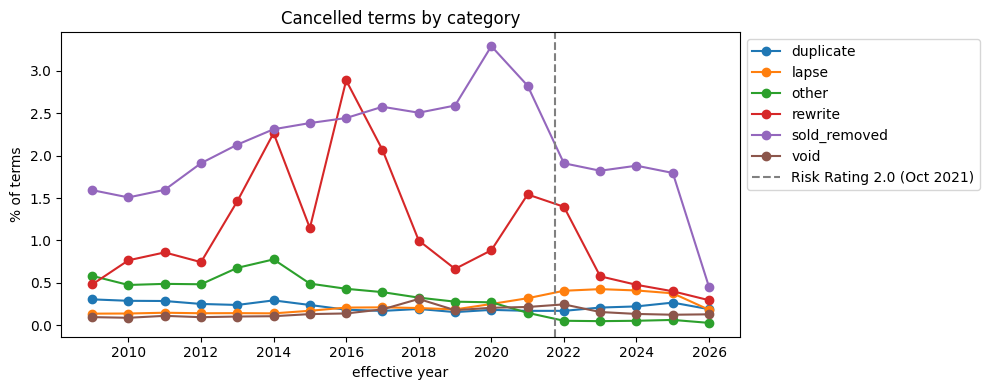

In [11]:
# Step 2.2b Chart
ax = cancel_pct.drop(columns="not_cancelled").plot(figsize=(10, 4), marker="o")
ax.axvline(2021.75, color="grey", linestyle="--", label="Risk Rating 2.0 (Oct 2021)")
ax.set(xlabel="effective year", ylabel="% of terms", title="Cancelled terms by category")
ax.legend(bbox_to_anchor=(1, 1))
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.savefig(REPORTS / "fig_cancel_category_by_year.png", dpi=150)
plt.show()

> **Our findings (2.2):**
> - **Only 3–6% of terms are cancelled in any year**, and most of those are not lapses. The total share was 3.2% in 2009, peaked at 6.3% in 2016, and was 3.0–3.3% in 2023–2025.
> - **Sold or removed is the largest category** in almost every year (1.5–3.3% of terms). It peaked in 2020 (3.29%), a year with many home sales.
> - **Rewrites are the second largest, and come in waves:** 2.26% in 2014, 2.89% in 2016 and 1.54% in 2021, against 0.4–0.9% in other years. The waves follow program changes that required terms to be re-rated: HFIAA (2014) and Risk Rating 2.0 (2021–2022).
> - **Lapse is small but has roughly tripled:** about 0.14% of terms in 2009–2013, about 0.20% in 2016–2019, then 0.32% in 2021 and 0.41–0.43% in 2022–2024. The rise starts with Risk Rating 2.0, which brought yearly premium increases and the new lapse codes 28 and 30 (from October 2021). As a share of all cancellations, lapse grew from about 4% (2009) to about 13% (2023).
> - **"Other" almost disappears after 2021** (about 0.5% of terms before, 0.05% after). Under Risk Rating 2.0 the flood zone no longer sets the price, so cancellations after a map change (codes 09, 20 and 16, see 2.1c) became rare.
> - **Duplicates (0.16–0.31%) and voids (0.09–0.31%) stay small** in every year.
> - **2026 is incomplete:** its terms started this year and most haven't had time to be cancelled yet, so its lower rates are censoring, not a real drop (Section 7). Years after the cutoff are left out of the chart.
>
> **What this means for our targets:** cancellation for a lapse reason is rare (below 0.5% of terms a year), because most policyholders who leave simply **don't renew** instead of cancelling during the term. This is why we also build `NON_RENEWAL`, and why we expect it to be the larger lapse target.

#### 2.2c What explains the rewrite waves?
We count the rewrites by code and year. If the waves come from program changes, each wave should be driven by one code:
- **25** (rewrite to process an HFIAA refund) should peak around 2014;
- **22** (rewrite due to misrating) or **24** (rewrite to PRP after a map revision) may explain 2016 and 2021;
- **03** (rewrite for a common expiration date) should stay steady.

In [12]:
# Step 2.2c Rewrites by code and effective year (% of all terms in the year)
rewrite_codes = (con.sql(f'''
        SELECT eff_year, 
               {cancel_code_sql()} AS code, 
               COUNT(*) AS n
        FROM clean_policies
        WHERE {cancel_category_sql()} = 'rewrite' AND eff_year <= {CUTOFF.year}
        GROUP BY ALL
    ''').df()
    .pivot(index="eff_year", columns="code", values="n").fillna(0).astype(int))

rewrite_codes = rewrite_codes.loc[rewrite_codes.index.isin(terms_per_year[terms_per_year >= 10_000].index)]
rewrite_pct = (100 * rewrite_codes.div(terms_per_year.loc[rewrite_codes.index], axis=0)).round(2)
display(rewrite_codes)
rewrite_pct

code,03,22,24,25
eff_year,,,,
2009,2447,17158,2858,0
2010,2318,30520,2624,1
2011,2779,33983,2917,391
2012,1518,27319,3889,1753
2013,883,25659,33175,8103
2014,2354,23593,63862,12661
2015,724,21563,14155,12670
2016,375,23150,36334,63635
2017,463,21420,55477,10990


code,03,22,24,25
eff_year,,,,
2009,0.05,0.37,0.06,0.00
2010,0.05,0.66,0.06,0.00
2011,0.06,0.73,0.06,0.01
2012,0.03,0.59,0.08,0.04
2013,0.02,0.55,0.72,0.17
2014,0.05,0.52,1.41,0.28
2015,0.02,0.50,0.33,0.30
2016,0.01,0.54,0.85,1.49
2017,0.01,0.50,1.30,0.26


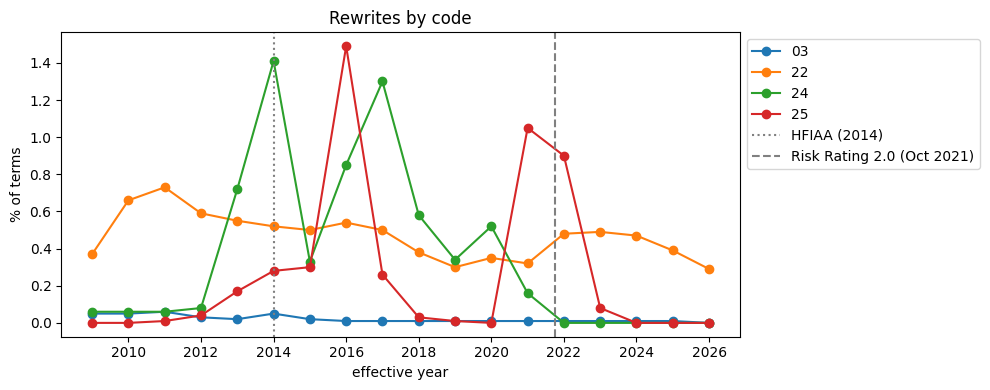

In [13]:
# Step 2.2d Chart
ax = rewrite_pct.plot(figsize=(10, 4), marker="o")
ax.axvline(2014, color="grey", linestyle=":", label="HFIAA (2014)")
ax.axvline(2021.75, color="grey", linestyle="--", label="Risk Rating 2.0 (Oct 2021)")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set(xlabel="effective year", ylabel="% of terms", title="Rewrites by code")
ax.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(REPORTS / "fig_rewrites_by_code.png", dpi=150)
plt.show()

> **Our findings (2.2c):** Code 25 (Cancel/Rewrite to Process HFIAA Refund), 24 (Cancel/Rewrite to PRP after Map Revision), and 22 (Cancel/Rewrite Due to Misrating) are the ones that is driving the rewrites with peaks between 2014 and 2016. 

#### 2.3 Does FEMA move the termination date when a policy is cancelled?
This decides when cover really stops. We take `eff_end` as the earlier of the cancellation date and the termination date.

In [14]:
# Step 2.3 Where does the cancellation date fall within the term? (% of cancelled terms)
con.sql(f'''
    WITH c AS (
        SELECT {cancel_category_sql()}                         AS category,
               CAST(cancellationDateOfFloodPolicy AS DATE)     AS cd,
               CAST(policyEffectiveDate AS DATE)               AS ts,
               CAST(policyTerminationDate AS DATE)             AS te
        FROM clean_policies
        WHERE cancellationDateOfFloodPolicy IS NOT NULL
    )
    SELECT category, 
           COUNT(*)                                                   AS n,
           ROUND(100 * AVG(CAST(cd = ts AS INTEGER)), 1)              AS on_start_pct,
           ROUND(100 * AVG(CAST(cd > ts AND cd < te AS INTEGER)), 1)  AS inside_pct,
           ROUND(100 * AVG(CAST(cd = te AS INTEGER)), 1)              AS on_end_pct,
           ROUND(100 * AVG(CAST(cd < ts AS INTEGER)), 2)              AS before_start_pct,
           ROUND(100 * AVG(CAST(cd > te AS INTEGER)), 2)              AS after_end_pct
    FROM c 
    GROUP BY 1 
    ORDER BY n DESC
''').df()

,category,n,on_start_pct,inside_pct,on_end_pct,before_start_pct,after_end_pct
0,sold_removed,1582313,1.1,97.9,0.0,0.97,0.0
1,rewrite,849247,95.7,1.8,0.5,2.03,0.0
2,other,268975,78.9,20.4,0.1,0.55,0.0
3,lapse,169875,31.7,66.7,0.6,1.05,0.0
4,duplicate,168927,87.5,10.7,0.6,1.15,0.0
5,void,113942,98.7,0.4,0.9,0.03,0.0


> **How we read it:** if `on_end_pct` is close to 100%, FEMA moves the termination date to the cancellation date. If `inside_pct` is large, the termination date stays at the scheduled end, and only `eff_end` shows when cover stopped. A large `on_start_pct` means many terms are cancelled **flat**: from their first day, as if they never existed (see the decision below).
> 
> A flat cancellation is a policy that is cancelled on its start date or before it. It never covers a single day. “Flat” is usually referred to as “cancelled from the beginning”. Usually the whole premium is refunded, as if the policy never existed.
>
> **Our findings:**
> - **FEMA keeps the scheduled termination date.** Almost no cancellation falls on the termination date (`on_end_pct` 0.0–0.9%), so `policyTerminationDate` is the planned end of the term, not when the cover stopped. We use `eff_end` (the earlier of the cancellation and termination dates) for when the cover really ended.
> - **Administrative cancellations happen on the start date.** Voids (98.7%), rewrites (95.7%), duplicates (87.5%) and "other" (78.9%) are mostly cancelled **flat**: the cover is ended from the term's first day, as if the term never existed. A rewritten term is replaced by a corrected term with the same start date; a void or duplicate never took effect; "other" is mostly eligibility and map changes cancelled with a full refund.
> - **About a third of lapses are flat (31.7%).** These are mostly renewals that were issued but never paid (non-payment, code 05), so in practice the policyholder did not renew. The other two thirds (66.7%) stop during the term, for example when the mortgage is paid off or the lender no longer requires the insurance.
> - **Sales happen during the term.** 97.9% of sold or removed cancellations fall inside the term, on the date of the sale.
> - **Cancellations before the start are rare (0.03–2.03%)** and are data errors, already flagged with `dq_cancel_before_effective`. No cancellation falls after the term's end.
>
> Because flat cancellations never gave cover, we treat them as not in force.

**Flat cancellations are not in force.** The cancellation date is the date the cover ends, not the date someone decided to cancel. When a term is cancelled "flat", the cover is ended from its first day, so the cancellation date equals the start date:

| Category | Why it is cancelled on the start date |
|---|---|
| rewrite | The term is replaced by a corrected term with the **same start date** (misrating, map revision, HFIAA refund). The cover continues under the new term. |
| void, duplicate | The term never took effect, or the building already had a policy. |
| other | Eligibility or map changes (for example a LOMA with lender release): cancelled from the start with a full refund. |
| lapse | Mostly non-payment of a **renewal** premium: the renewal term was issued but never paid. |

We give these terms no policy-years (`in_force` is False, `src/linkage.py`), so:
- a rewritten term doesn't look like a non-renewal;
- an unpaid renewal can't count as the previous term's renewal, so the previous term gets `NON_RENEWAL = 1`, which is what happened;
- `CANCEL_IN_TERM` measures lapses **during** a term, and lapses at renewal are measured by `NON_RENEWAL`. The two targets don't overlap.

The cost: a brand-new policy that is cancelled flat for non-payment, with no term before it, drops out completely. Step 10.2 shows how many terms are left out this way.

In [15]:
from src.targets import cancel_code_sql

con.sql(f'''
    SELECT {cancel_category_sql()} as category,
           COUNT(*) AS n,
           ROUND(100 * AVG(CAST(CAST(cancellationDateOfFloodPolicy AS DATE)
                                <= CAST(policyEffectiveDate AS DATE) AS INTEGER)), 1) AS flat_pct,
           ROUND(100 * AVG(CAST(CAST(originalNBDate AS DATE) < CAST(policyEffectiveDate AS DATE) AS INTEGER))
                 FILTER (WHERE CAST(cancellationDateOfFloodPolicy AS DATE) <= CAST(policyEffectiveDate AS DATE)), 1)
               AS flat_that_are_renewals_pct
    FROM clean_policies
    WHERE {cancel_category_sql()} = 'lapse'
    GROUP BY 1 ORDER BY n DESC
''').df()

,category,n,flat_pct,flat_that_are_renewals_pct
0,lapse,169875,32.7,64.3


In the table above, we have calculated how many policies are not paid (flat outright) and renewed. Rewrites, voids, duplicates and “other” are cancelled flat because the term was replaced or never took effect. Flat lapses are mostly unpaid renewals. FEMA keeps the scheduled termination date (on_end_pct about 0%).


In [16]:
# Step 2.4 Log
n_cancelled = scalar(con, "SELECT COUNT(*) FROM clean_policies WHERE cancellationVoidanceReasonCode IS NOT NULL")
log.add("policies", "cancellationVoidanceReasonCode", "decode to cancel_category (src/targets.py)",
        "lapse = 05, 28, 30, 52; rewrites, duplicates and voids are not lapse", n_cancelled)

### Section 3. Build the policy key
FEMA publishes no policy ID (`id` identifies the record, not the policy), so we rebuild one from fields that stay the same across renewals.

#### 3.1 Define the composite key
`originalNBDate` + `originalConstructionDate` + `censusGeoid` + `reportedZipCode` + `numberOfFloorsInInsuredBuilding`.

We hash the five values into one number with `key_expr`. If any field is missing, the key is NULL. We can't link those rows, so we set their claim and renewal targets to NULL (unknown), not 0.

We first included `occupancyType` too, but Step 6.2 showed that its coding changed with Risk Rating 2.0, so one house got two keys. We left it out (see 6.2) and keep it as a feature instead.

In [17]:
# Step 3.1a The SQL for each field (the same expressions run on policies and claims)
pd.Series(KEY_FIELDS, name="sql").to_frame()

,sql
originalNBDate,CAST(originalNBDate AS DATE)
originalConstructionDate,CAST(originalConstructionDate AS DATE)
censusGeoid,geoid11
reportedZipCode,zip5
numberOfFloorsInInsuredBuilding,TRY_CAST(numberOfFloorsInInsuredBuilding AS IN...


In [18]:
# Step 3.1b % of rows missing each key field
def missing_by_field(view):
    parts = ", ".join(f'ROUND(100 * AVG(CAST(({e}) IS NULL AS INTEGER)), 3) AS "{f}"' for f, e in KEY_FIELDS.items())
    return con.sql(f'''SELECT COUNT(*) AS rows, 
                              {parts},
                              ROUND(100 * AVG(CAST(({key_expr(KEY)}) IS NULL AS INTEGER)), 3) AS any_key_field
                       FROM {view}''').df()

key_missing = pd.concat({"policies": missing_by_field("clean_policies"),
                         "claims": missing_by_field("clean_claims")}).droplevel(1).T
key_missing

,policies,claims
rows,7.473946e+07,2714607.000
originalNBDate,2.000000e-02,0.003
originalConstructionDate,6.100000e-02,0.075
censusGeoid,4.160000e-01,4.982
reportedZipCode,0.000000e+00,0.000
numberOfFloorsInInsuredBuilding,7.800000e-02,0.635
any_key_field,5.110000e-01,5.569


#### 3.2 Build the chain on one pilot state
We check every step on `PILOT` (i.e. the test state) before running all states. `create_chain` (`src/linkage.py`) makes five objects, each built from the one before:

| Name | One row per | Made by |
|---|---|---|
| `pilot_terms` | policy term | `terms_sql`: key, dates, cancellation category, `eff_end` |
| `pilot_linked` | in-force term | `linked_terms_sql`: term order, gaps, collisions, `renewed` |
| `pilot_periods` | policy-year | `periods_sql`: splits multi-year terms |
| `pilot_claims_k` | claim | `claims_sql`: the same key on the claims |
| `pilot_links` | claim | `claim_links_sql`: the policy-year each claim belongs to |

We use `materialize=True` to store the last two as tables, so the queries below don't recompute them.

In [19]:
# Step 3.2 Pilot chain
con.execute(f"CREATE OR REPLACE VIEW pilot_policies AS SELECT * FROM clean_policies WHERE propertyState = '{PILOT}'")
con.execute(f"CREATE OR REPLACE VIEW pilot_claims AS SELECT * FROM clean_claims WHERE state = '{PILOT}'")

t0 = time.time()
pilot = create_chain(con, "pilot_policies", "pilot_claims", "pilot_", fields=KEY, materialize=True)
print(f"{PILOT}: built in {time.time() - t0:.0f} s")
pilot

NY: built in 2 s


{'terms': 'pilot_terms',
 'linked': 'pilot_linked',
 'periods': 'pilot_periods',
 'claims': 'pilot_claims_k',
 'links': 'pilot_links'}

#### 3.3 Key collisions
We count keys with more than one term starting in the same year (rewritten terms not counted). These are likely different properties sharing a key.

In [20]:
# Step 3.3a Terms by the number of terms of the same key starting in the same year
con.sql(f'''
    SELECT starts_same_year, 
           COUNT(*) AS terms,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM pilot_linked
    WHERE key_complete
    GROUP BY 1 
    ORDER BY 1
''').df()

,starts_same_year,terms,pct
0,0.0,214,0.01
1,1.0,2554828,96.56
2,2.0,38498,1.46
3,3.0,13476,0.51
4,4.0,8332,0.31
5,5.0,4635,0.18
6,6.0,3984,0.15
7,7.0,3703,0.14
8,8.0,2136,0.08
9,9.0,1638,0.06


In [21]:
# Step 3.3b One colliding key, all its terms
key = scalar(con, f"SELECT policy_key FROM pilot_linked WHERE dq_key_collision ORDER BY hash(policy_key) LIMIT 1")
if key is None:
    print("no collisions in", PILOT)
else:
    display(con.sql(f'''
        SELECT term_no, 
               term_start, 
               term_end, 
               eff_end, 
               cancel_category, 
               policy_count, 
               gap_to_next_days, 
               renewed
        FROM pilot_linked 
        WHERE policy_key = {key} 
        ORDER BY term_no
    ''').df())

,term_no,term_start,term_end,eff_end,cancel_category,policy_count,gap_to_next_days,renewed
0,1,2017-04-29,2018-04-29,2018-04-29,not_cancelled,1,-365,True
1,2,2017-04-29,2018-04-29,2018-04-29,not_cancelled,1,-365,True
2,3,2017-04-29,2018-04-29,2018-04-29,not_cancelled,1,-365,True
3,4,2017-04-29,2018-04-29,2018-04-29,not_cancelled,1,-365,True
4,5,2017-04-29,2018-04-29,2018-04-29,not_cancelled,1,0,True
5,6,2018-04-29,2019-04-29,2019-04-29,not_cancelled,1,-365,True
6,7,2018-04-29,2019-04-29,2019-04-29,not_cancelled,1,-365,True
7,8,2018-04-29,2019-04-29,2019-04-29,not_cancelled,1,-365,True
8,9,2018-04-29,2019-04-29,2019-04-29,not_cancelled,1,-365,True
9,10,2018-04-29,2019-04-29,2019-04-29,not_cancelled,1,0,True


### Section 4. Link terms into policies
We group terms by key and order them by effective date to rebuild each policy's history, then split every term into policy-years.

#### 4.1 Order terms and number them
Within each key, we sort the terms by `term_start` and number them (`term_no`), and add the previous term's end and the next term's start.

In [22]:
# Step 4.1 One policy with at least 4 terms and no collision
key = scalar(con, f'''SELECT policy_key FROM pilot_linked
                      WHERE n_terms_key >= 4 AND NOT dq_key_collision
                      ORDER BY hash(policy_key) LIMIT 1''')
con.sql(f'''
    SELECT term_no,
           term_start, 
           term_end, 
           eff_end,
           cancel_category, 
           prev_end,
           next_start,
           gap_to_next_days,
           renewed
    FROM pilot_linked 
    WHERE policy_key = {key}
    ORDER BY term_no
''').df()

,term_no,term_start,term_end,eff_end,cancel_category,prev_end,next_start,gap_to_next_days,renewed
0,1,2014-01-11,2015-01-11,2015-01-11,not_cancelled,NaT,2015-01-11,0,True
1,2,2015-01-11,2016-01-11,2016-01-11,not_cancelled,2015-01-11,2016-01-11,0,True
2,3,2016-01-11,2017-01-11,2017-01-11,not_cancelled,2016-01-11,2017-01-11,0,True
3,4,2017-01-11,2018-01-11,2018-01-11,not_cancelled,2017-01-11,2018-01-11,0,True
4,5,2018-01-11,2019-01-11,2019-01-11,not_cancelled,2018-01-11,2019-01-11,0,True
5,6,2019-01-11,2020-01-11,2020-01-11,not_cancelled,2019-01-11,2020-01-11,0,True
6,7,2020-01-11,2021-01-11,2021-01-11,not_cancelled,2020-01-11,2021-01-11,0,True
7,8,2021-01-11,2022-01-11,2022-01-11,not_cancelled,2021-01-11,2022-01-11,0,True
8,9,2022-01-11,2023-01-11,2023-01-11,not_cancelled,2022-01-11,2023-01-11,0,True
9,10,2023-01-11,2024-01-11,2024-01-11,not_cancelled,2023-01-11,2024-01-11,0,True


#### 4.2 Gaps and overlaps between terms
We measure the gap between one term's end and the next term's start. Large gaps or overlaps suggest linkage errors, or lapses where the policyholder came back later.

In [23]:
# Step 4.2 Gap to the next term of the same key
con.sql(f'''
    SELECT CASE WHEN gap_to_next_days IS NULL                     THEN 'g: last term of the key'
                WHEN gap_to_next_days < -30                       THEN 'a: overlap > 30 days'
                WHEN gap_to_next_days < 0                         THEN 'b: overlap 1-30 days'
                WHEN gap_to_next_days = 0                         THEN 'c: renewed on the day'
                WHEN gap_to_next_days <= {RENEWAL_WINDOW_DAYS}    THEN 'd: gap within the renewal window'
                WHEN gap_to_next_days <= 365                      THEN 'e: gap up to 1 year (lapse, then back)'
                ELSE 'f: gap > 1 year' END AS gap,
           COUNT(*) AS terms,
           ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS pct
    FROM pilot_linked
    WHERE key_complete
    GROUP BY 1 
    ORDER BY 1
''').df()

,gap,terms,pct
0,a: overlap > 30 days,63505,2.40
1,b: overlap 1-30 days,1040,0.04
2,c: renewed on the day,2116591,80.00
3,d: gap within the renewal window,2405,0.09
4,"e: gap up to 1 year (lapse, then back)",16214,0.61
5,f: gap > 1 year,2223,0.08
6,g: last term of the key,443798,16.77


> **Our findings:** About 75% of the policies are renewed on the same day. 21% lapsed, but eventually get renewed within 1 year.

#### 4.3 Split multi-year terms into policy-years
Our unit of prediction is the policy-year. We split terms by their **dates**, not by `policyTermIndicator` (see notebook 02, 2.4.6e–f):

- Each period starts on the term's anniversary and lasts one year, so a 3-year term becomes 3 rows.
- We **keep** a short last period (for example the last 0.77 year of a 2.77-year term), with `exposure` below 1. Dropping it would hide the claims and cancellations in those months.
- We add a leftover shorter than 30 days to the period before it, so a 368-day term stays one period.
- Cover stops at `eff_end`: we remove the periods after a cancellation and cut the last one short.

In [24]:
# Step 4.3a Terms and periods by the number of scheduled periods
con.sql(f'''
    SELECT n_scheduled,
           COUNT(*) FILTER (WHERE period_no = 0) AS terms,
           COUNT(*)                              AS periods,
           MIN(term_days)                        AS min_term_days,
           MAX(term_days)                        AS max_term_days,
           ROUND(SUM(exposure), 1)               AS exposure_years
    FROM pilot_periods
    GROUP BY 1 
    ORDER BY 1
''').df()

,n_scheduled,terms,periods,min_term_days,max_term_days,exposure_years
0,1,2654172,2654172,7,366,2631086.2
1,2,90,180,396,733,167.9
2,3,4980,14940,762,1096,12487.8


In [25]:
# Step 4.3b One multi-year term, period by period
tid = scalar(con, f"SELECT id FROM pilot_periods WHERE n_scheduled >= 3 ORDER BY hash(id) LIMIT 1")
if tid is None:
    print("no multi-year terms in", PILOT)
else:
    display(con.sql(f'''
        SELECT  id, 
                term_start, 
                term_end, 
                eff_end, 
                cancel_category, 
                period_no, 
                period_start, 
                period_end,
                ROUND(exposure, 3) AS exposure, 
                is_last_period
        FROM pilot_periods 
        WHERE id = '{tid}' 
        ORDER BY period_no
    ''').df())

,id,term_start,term_end,eff_end,cancel_category,period_no,period_start,period_end,exposure,is_last_period
0,170760557,2013-03-08,2015-12-29,2015-12-29,not_cancelled,0,2013-03-08,2014-03-08,0.999,False
1,170760557,2013-03-08,2015-12-29,2015-12-29,not_cancelled,1,2014-03-08,2015-03-08,0.999,False
2,170760557,2013-03-08,2015-12-29,2015-12-29,not_cancelled,2,2015-03-08,2015-12-29,0.810,True


In [26]:
# Step 4.3c The periods of a term add up to the time it was in force (expect mismatched = 0)
con.sql(f'''
    WITH t AS (
        SELECT id,
               SUM(exposure) AS exposure_sum,
               ANY_VALUE(GREATEST(date_diff('day', term_start, eff_end), 0)) / 365.25 AS exposure_expected
        FROM pilot_periods
        GROUP BY id
    )
    SELECT COUNT(*) AS terms,
           COUNT(*) FILTER (WHERE ABS(exposure_sum - exposure_expected) > 0.001) AS mismatched,
           ROUND(MAX(ABS(exposure_sum - exposure_expected)), 4) AS max_diff_years
    FROM t
''').df()

,terms,mismatched,max_diff_years
0,2659242,0,0.0


> **Our findings (4.3)**
>
> **How we compute the periods and their exposure.** We split each term into policy-years on its anniversaries. The number of periods comes from the term length, with a 30-day tolerance:
>
> $$n_{\text{scheduled}} = \max\left(1,\ \left\lceil \frac{\text{term\_days} - 30}{365.25} \right\rceil\right)$$
>
> Each period ends on the next anniversary (the last one at `term_end`), cut at `eff_end` so cover after a cancellation is not counted. Its exposure is its length in years:
>
> $$\text{exposure} = \frac{\text{period\_end} - \text{period\_start}\ \text{(days)}}{365.25}$$
>
> We divide by 365.25 so that leap years average out: a normal year gives 0.999 and a year with 29 February gives 1.002. `period_end` is not counted as a day of cover.
>
> - **Almost every term is one year.** In SC, 2,654,172 of 2,659,242 terms (99.8%) have one period. Only 5,070 terms (0.2%) are multi-year: 90 two-year and 4,980 three-year terms. Splitting them turns 2,659,242 terms into 2,669,292 policy-years, so the split changes little in count but makes every row comparable.
> - **The 30-day tolerance works as intended.** One-period terms go up to 366 days, and the shortest three-period term is 762 days (2 years + 32 days, just over the tolerance). A few days past an anniversary does not create an extra period.
> - **Short last periods are kept.** In our example (Step 4.3b), a term from 2013-03-08 to 2015-12-29 (1,026 days) became three periods with exposures 0.999, 0.999 and 0.810, which add up to 2.809 years = 1,026 / 365.25.
> - **Exposure is below 1 on average.** The mean exposure per period is 0.990 (2,643,742 years over 2,669,292 periods). One-year terms average 0.991 because of mid-term cancellations and short terms (as short as 7 days). Three-year terms average 2.51 years out of 3 (0.84 per period), because of cancellations and short last periods.
> - **Nothing is lost or double-counted.** Step 4.3c shows that the periods of each term add up to its time in force: `mismatched = ___` (max difference ___ years).
>
> **What it means for us:** every row now covers at most one year, so claim and lapse rates are comparable across policies, like a 12-month PD per loan-year in credit risk. Here "exposure" means **time at risk in years** (the actuarial meaning), not the amount at risk like EAD in credit risk; the amount at risk is the coverage, which we use as a feature in notebook 05. Since about 99% of periods are about one year (mean 0.990), exposure changes little for most rows. We keep it to describe the data and compute rates per policy-year, but we do **not** use it as a model input: a period is short *because* it was cancelled, so it would leak the outcome. If we need a time input, we will use the scheduled length of the period (known at its start) instead.

#### 4.4 What happened to every term (pilot)
We count where every pilot term ends up, from all terms in the state to the policy-years we keep.

In [27]:
# Step 4.4 Pilot waterfall (each term is counted in the first reason that applies)
con.sql(f'''
    SELECT COUNT(*)                                                                    AS terms_in_state,
           COUNT(*) FILTER (WHERE cancel_category IN ('void', 'duplicate'))             AS void_or_duplicate,
           COUNT(*) FILTER (WHERE cancel_category NOT IN ('void', 'duplicate') AND flat_cancel) AS flat_cancelled,
           COUNT(*) FILTER (WHERE cancel_category NOT IN ('void', 'duplicate') AND NOT flat_cancel
                            AND term_end <= term_start)                                  AS end_not_after_start,
           COUNT(*) FILTER (WHERE in_force)                                             AS terms_in_force,
           COUNT(*) FILTER (WHERE in_force AND NOT key_complete)                        AS in_force_key_incomplete,
           (SELECT COUNT(*) FROM pilot_periods)                                         AS policy_years
    FROM pilot_terms
''').df().T.rename(columns={0: PILOT})

,NY
terms_in_state,2705125
void_or_duplicate,11386
flat_cancelled,34448
end_not_after_start,49
terms_in_force,2659242
in_force_key_incomplete,13466
policy_years,2669292


### Section 5. Link claims to policy-years
We attach each claim to the policy-year that was in force on its date of loss.

#### 5.1 Match on key and date of loss
We match on the same key, with `loss_date` on or after `period_start` and before `period_end`, so a loss on the renewal date belongs to the new term. We leave claims before 2010 out of the rates: the policies data starts around 2009, so older claims have no term to match.

In [28]:
# Step 5.1a Overall
con.sql(claim_match_sql(pilot["links"])).df()

,claims,matched_pct,matched_multi_pct,outside_term_pct,key_not_found_pct,key_incomplete_pct
0,96676,95.86,3.01,0.5,0.08,0.55


In [29]:
# Step 5.1b By year of loss
con.sql(claim_match_sql(pilot["links"], "loss_year")).df()

,loss_year,claims,matched_pct,matched_multi_pct,outside_term_pct,key_not_found_pct,key_incomplete_pct
0,2010,3082,97.24,1.75,0.42,0.19,0.39
1,2011,20605,96.59,2.40,0.34,0.03,0.63
2,2012,57927,95.81,3.21,0.40,0.06,0.52
3,2013,1007,96.03,1.59,0.89,0.00,1.49
4,2014,1557,89.79,3.15,5.14,0.13,1.80
5,2015,327,96.64,1.22,0.31,0.00,1.83
6,2016,227,95.59,1.76,2.20,0.00,0.44
7,2017,876,95.78,3.42,0.23,0.11,0.46
8,2018,885,96.72,2.60,0.11,0.00,0.56
9,2019,628,98.41,0.48,0.48,0.00,0.64


#### 5.2 Unmatched and multiply matched claims
We sort every claim into one of these outcomes:
- `key_incomplete`: a key field is missing on the claim.
- `key_not_found`: no term in this state has the key (the property's policy is outside the data, or a key field was recorded differently on the claim).
- `outside_term`: the key exists, but no policy-year covers the date of loss.
- `matched_multi`: two overlapping terms (a colliding key). We assign the claim to the term that started last.

In [30]:
# Step 5.2 Three outside_term claims, with all the terms of their key
ex = con.sql(f'''SELECT claim_id, 
                        loss_date, 
                        policy_key 
                 FROM pilot_links
                 WHERE match_status = 'outside_term' AND loss_year >= 2010
                 ORDER BY hash(claim_id) LIMIT 3
            ''').df()

for _, r in ex.iterrows():
    print(f"claim {r['claim_id']}, loss on {r['loss_date']:%Y-%m-%d}")
    display(con.sql(f'''SELECT term_start, 
                               term_end, 
                               eff_end, 
                               cancel_category, 
                               in_force
                        FROM pilot_terms WHERE policy_key = {int(r["policy_key"])}
                        ORDER BY term_start
                    ''').df())

claim 5552457, loss on 2012-10-29


,term_start,term_end,eff_end,cancel_category,in_force
0,2009-12-31,2010-12-31,2010-12-31,not_cancelled,True
1,2010-12-31,2011-12-31,2011-12-31,not_cancelled,True
2,2011-12-31,2012-12-31,2011-12-31,rewrite,False
3,2012-12-31,2013-12-31,2013-12-31,not_cancelled,True


claim 7642052, loss on 2022-12-22


,term_start,term_end,eff_end,cancel_category,in_force
0,2015-10-30,2016-10-30,2016-10-30,not_cancelled,True
1,2016-10-30,2017-10-30,2017-10-30,not_cancelled,True
2,2017-10-30,2018-10-30,2018-10-30,not_cancelled,True
3,2018-10-30,2019-10-30,2019-10-30,not_cancelled,True
4,2019-10-30,2020-10-30,2020-10-30,not_cancelled,True
5,2020-10-30,2021-10-30,2021-10-30,not_cancelled,True
6,2021-10-30,2022-10-30,2022-10-30,not_cancelled,True
7,2022-10-30,2023-10-30,2022-10-30,rewrite,False


claim 6316169, loss on 2012-10-29


,term_start,term_end,eff_end,cancel_category,in_force
0,2009-10-17,2010-10-17,2010-10-17,not_cancelled,True
1,2010-10-17,2011-10-17,2011-10-17,not_cancelled,True
2,2011-10-17,2012-10-17,2012-10-17,not_cancelled,True
3,2012-10-17,2013-10-17,2012-10-17,rewrite,False
4,2013-10-17,2014-10-17,2014-10-17,not_cancelled,True


### Section 6. Linkage quality
We measure how reliable our rebuilt policies are. Every later result depends on this.

#### 6.1 Match rate, collision rate and key completeness (pilot)
We make the same tables for every state in Section 10.1, after the full run.

In [31]:
# Step 6.1 Pilot summary
display(con.sql(term_quality_sql(pilot["periods"])).df())
display(con.sql(claim_match_sql(pilot["links"])).df())

,terms,key_complete_pct,collision_pct,multi_year_pct,renewed_pct,avg_terms_per_key
0,2659242,99.49,3.43,0.191,82.17,11.5


,claims,matched_pct,matched_multi_pct,outside_term_pct,key_not_found_pct,key_incomplete_pct
0,96676,95.86,3.01,0.5,0.08,0.55


#### 6.2 Sensitivity to alternative keys
We rebuild the key with one field added or left out and compare. A good key must be **unique** and **stable**: different houses get different keys, and the same house keeps the same key every year and in the claims file. Uniqueness alone is not enough: a key made from the row number is 100% unique but links nothing.

- **Fewer collisions** means the key doesn't merge different houses.
- **More matched claims and renewals** means the key doesn't split one house into several keys.

The table compares our chosen 5-field key with the old 6-field key (with `occupancyType`) and with keys that leave out one more field.

In [32]:
# Step 6.2 Compare the keys in ALT_KEYS on the pilot state
alt_keys = compare_keys(con, "pilot_policies", "pilot_claims", ALT_KEYS)
alt_keys

,key,n_fields,terms,key_complete_pct,collision_pct,multi_year_pct,renewed_pct,avg_terms_per_key,claims,matched_pct,matched_multi_pct,outside_term_pct,key_not_found_pct,key_incomplete_pct
0,chosen (5 fields),5,2659242,99.49,3.43,0.191,82.17,11.50,96676,95.86,3.01,0.50,0.08,0.55
1,with occupancy (old 6 fields),6,2659242,99.49,3.24,0.191,77.63,7.92,96676,72.12,2.10,24.93,0.30,0.55
2,without tract,4,2659242,99.78,3.87,0.191,82.25,11.89,96676,95.78,3.47,0.50,0.07,0.18
3,without zip,4,2659242,99.49,3.50,0.191,82.17,11.54,96676,95.80,3.07,0.50,0.08,0.55
4,without floors,4,2659242,99.68,4.31,0.191,82.44,12.40,96676,95.27,3.84,0.45,0.06,0.39
5,without construction date,4,2659242,99.49,9.68,0.191,82.68,13.55,96676,88.87,10.03,0.47,0.07,0.55


In [33]:
# Step 6.2b Occupancy codes by year: policies vs claims (does the coding change?)
display(con.sql('''
    SELECT eff_year AS yr, occupancyType, COUNT(*) AS n
    FROM pilot_policies
    GROUP BY ALL
''').df().pivot(index="yr", columns="occupancyType", values="n").fillna(0).astype(int))

con.sql('''
    SELECT YEAR(CAST(dateOfLoss AS DATE)) AS yr, occupancyType, COUNT(*) AS n
    FROM pilot_claims
    GROUP BY ALL
''').df().pivot(index="yr", columns="occupancyType", values="n").fillna(0).astype(int)

occupancyType,1,2,3,4,6,11,12,13,14,15,16,17,18,19
yr,,,,,,,,,,,,,,
2009,125984,13009,4631,5140,1395,0,0,0,0,0,0,0,0,0
2010,124882,12746,4577,5147,1554,0,0,0,0,0,0,0,0,0
2011,128666,13075,4769,5460,1859,0,0,0,0,0,0,0,0,0
2012,131682,13638,5339,5827,2376,0,0,0,0,0,0,0,0,0
2013,145766,16940,7052,6135,4309,0,0,0,0,0,0,0,0,0
2014,139263,16582,7235,3785,6894,0,0,0,0,0,0,0,0,0
2015,135664,15802,7044,2686,8058,0,0,0,0,0,0,0,0,0
2016,132775,15210,7270,1594,9244,0,0,0,0,0,0,0,0,0
2017,129420,14858,6880,1698,8713,0,0,0,0,0,0,0,0,0


occupancyType,<NA>,1,2,3,4,6,11,12,13,14,15,16,17,18,19
yr,,,,,,,,,,,,,,,
1978,18,3077,676,82,320,0,0,0,0,0,0,0,0,0,0
1979,28,7561,1449,174,904,0,0,0,0,0,0,0,0,0,0
1980,7,5085,1182,153,801,0,0,0,0,0,0,0,0,0,0
1981,0,1743,384,61,290,0,0,0,0,0,0,0,0,0,0
1982,0,1609,264,30,183,0,0,0,0,0,0,0,0,0,0
1983,0,2050,380,43,210,0,0,0,0,0,0,0,0,0,0
1984,0,2907,411,97,470,0,0,0,0,0,0,0,0,0,0
1985,0,3187,218,51,166,0,2,0,0,0,0,0,0,0,0
1986,0,629,47,14,89,0,0,0,0,0,0,0,0,0,0


> **Our findings:**
>
> - **`occupancyType` is not stable for the same house, so we dropped it from the key.** Risk Rating 2.0 replaced the 1-digit codes with 2-digit codes (only 2-digit codes from 2023 on), and the claims file carries the new codes even for losses from 2017–2020, while the policies keep the code of their time (Step 6.2b). So one house got two keys, and with occupancy in the key 25% of the pilot claims found their key but no term covering the loss date. Without it, matched claims rose from 72.1% to 95.9% and renewals from 77.6% to 82.2%, while collisions rose only from 3.24% to 3.43%.
> - **We did not harmonize the codes instead**, because old and new codes do not map one-to-one: old code 1 (single family) became 11, 14 (mobile home) or 16 (unit in a multi-unit building). The only safe grouping, residential vs non-residential, would separate almost nothing. We keep occupancy as a feature in notebook 05, grouped so old and new codes mean the same thing.
> - **We keep the other five fields.** Leaving any of them out adds collisions without improving the matches; construction date matters most (collisions 3.24% to 8.68%, matched claims down to 67.8%).
> - _(after the rerun: check the new table, where the chosen 5-field key should show about 96% matched claims and 3.4% collisions)_

### Section 7. Filtering the Model Population
We must not label a policy-year 0 when its outcome can't be observed yet. Otherwise every recent policy-year would look like "no claim, no cancellation", and our predicted rates would be pulled down.

| Flag | True when | Effect |
|---|---|---|
| (removed) | the period starts after `CUTOFF` | we drop the row |
| `censored_claim` | the period ends after `CUTOFF - CLAIM_LAG_DAYS` | `CLAIM_IN_TERM` is NULL |
| `censored_cancel` | the period ends after `CUTOFF` and no cancellation is seen yet | `CANCEL_IN_TERM` is NULL |
| `censored_renewal` | last period, and its renewal window ends after `CUTOFF` | `NON_RENEWAL` is NULL |

#### 7.1 How long until a claim shows up in the data?
The claims file has no report date, so we can't measure the delay directly. What we can see is how settled the recent losses are. Losses close to the cutoff have a lower share with a payment, because they are still being handled. The months where `paid_pct` is clearly below its usual level show us how long claims take to settle.

Claim counts move with storms, so we read the **paid share**, not the count.

The formula of how the paid percentage was derived is shown below. 
$$\text{paid\_pct} = 100 \times \frac{\text{number of claims with total\_paid} > 0}{\text{number of claims}}$$


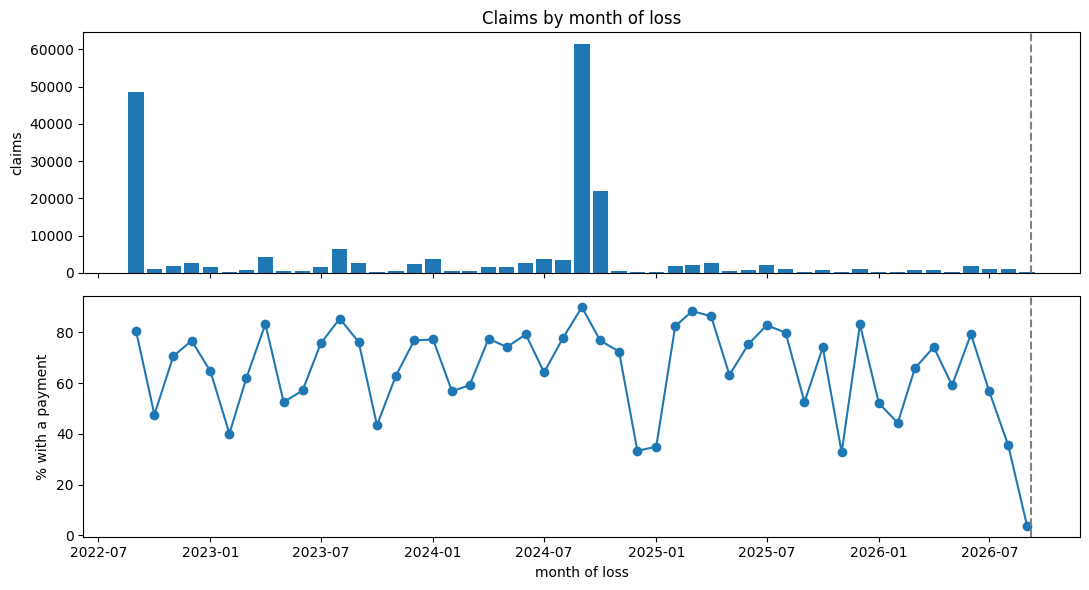

,loss_month,claims,paid_pct
31,2025-04-01,2712,86.3
32,2025-05-01,551,63.2
33,2025-06-01,805,75.3
34,2025-07-01,2009,82.8
35,2025-08-01,953,79.9
36,2025-09-01,265,52.5
37,2025-10-01,757,74.1
38,2025-11-01,98,32.7
39,2025-12-01,1044,83.1
40,2026-01-01,211,52.1


In [34]:
# Step 7.1 Claims by month of loss, last 4 years before the cutoff
recent = con.sql(f'''
    SELECT date_trunc('month', loss_date) AS loss_month,
           COUNT(*) AS claims,
           ROUND(100 * AVG(CAST(total_paid > 0 AS INTEGER)), 1) AS paid_pct
    FROM clean_claims
    WHERE loss_date >= DATE '{CUTOFF}' - INTERVAL 48 MONTH
    GROUP BY 1 ORDER BY 1
''').df()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax1.bar(recent["loss_month"], recent["claims"], width=25)
ax1.set(ylabel="claims", title="Claims by month of loss")
ax2.plot(recent["loss_month"], recent["paid_pct"], marker="o")
ax2.set(ylabel="% with a payment", xlabel="month of loss")
for ax in (ax1, ax2):
    ax.axvline(pd.Timestamp(CUTOFF), color="grey", linestyle="--")
plt.tight_layout()
plt.savefig(REPORTS / "fig_claim_settlement_by_loss_month.png", dpi=150)
plt.show()
recent.tail(18)

In [35]:
# Step 7.2 Share of pilot policy-years censored for the claim target, by delay
cols = ", ".join(f"ROUND(100 * AVG(CAST(period_end > DATE '{CUTOFF}' - {d} AS INTEGER)), 2) AS censored_{d}d"
                 for d in (0, 90, 180, 365))
con.sql(f"SELECT {cols} FROM pilot_periods WHERE period_start <= DATE '{CUTOFF}'").df()

,censored_0d,censored_90d,censored_180d,censored_365d
0,4.77,6.08,7.12,9.75


> **Our findings:**
>
> - **What the delay means.** `CLAIM_LAG_DAYS` is the time we give a claim to appear in the data after a policy-year ends. A policy-year that ends less than this before the cutoff (2026-09-08) is marked `censored_claim`: a "no claim" there may only mean "not settled yet", so we leave it out of the claim target instead of counting it as 0.
> - **How long claims take (7.1).** The share of claims with a payment is 75–86% in normal months, but falls in the last months before the cutoff: 56.7% for July 2026, 35.6% for August and 3.8% for September. So most claims are settled within about 3 months of the loss. Some months earlier in the year are also low (32.7% in November 2025, 44–52% in January–February 2026), but these have few claims (80–211), so we read them as noise, not lag.
> - **What it costs (7.2).** Of the pilot policy-years that started by the cutoff, 4.77% are still in force at the cutoff (0 days, always censored). Censoring rises to 6.08% at 90 days, 7.12% at 180 days and 9.75% at 365 days.
> - **Our choice: we keep `CLAIM_LAG_DAYS = 365`.** 7.1 suggests 90–180 days would cover most settlements, but 7.1 measures only the time to *payment*. The claims file has no report date, so we cannot see claims that are *filed* late, and a claim also needs time to be added to FEMA's published data. A year is a safe margin, and it costs only 2.63 percentage points more than 180 days. Since our test year (2023) ends well before the cutoff, the lost policy-years are ones we would not train or test on anyway.

### Section 8. Define the targets
We build our three targets per policy-year with `labeled_periods_sql` (`src/targets.py`).

| Target | 1 when | NULL when |
|---|---|---|
| `CLAIM_IN_TERM` | at least one linked claim with a loss in the period | key incomplete, or `censored_claim` |
| `CLAIM_PAID_IN_TERM` | at least one linked claim with a payment | same as above (alternative target) |
| `CANCEL_IN_TERM` | cancelled **during** the period for a lapse reason (flat cancellations are not in force, see Step 2.3) | `censored_cancel` |
| `SOLD_REMOVED_IN_TERM` | cancelled because the building or contents were sold or removed | `censored_cancel` |
| `NON_RENEWAL` | last period of the term, and no term of the same key starts within ±60 days of `eff_end` | key incomplete, or `censored_renewal`; 0 for the inner years of a multi-year term |

We mark with `community_sanctioned` the terms whose community was suspended or withdrawn from the NFIP around the term's end. Their non-renewal may be involuntary, so in notebook 04 we can leave them out.

In [38]:
# Step 8.0 Labeled pilot view
con.execute(f'''CREATE OR REPLACE VIEW pilot_labeled AS
    {labeled_periods_sql(pilot["periods"], pilot["links"], "clean_community", CUTOFF,
                         CLAIM_LAG_DAYS, RENEWAL_WINDOW_DAYS)}''')
con.sql(target_rates_sql("pilot_labeled", "period_year")).df()

,period_year,periods,exposure_years,claim_labeled,claim_pct,claim_paid_pct,cancel_labeled,cancel_pct,sold_removed_pct,non_renewal_labeled,non_renewal_pct
0,2009,147079,145971.0,146277,1.715,1.276,147079,0.126,1.111,146277,18.047
1,2010,146259,145233.0,145505,5.477,4.612,146259,0.132,1.038,145505,18.709
2,2011,150231,149506.0,149115,14.437,13.078,150231,0.105,1.136,149115,11.663
3,2012,156099,154903.0,154596,29.873,28.552,156099,0.101,1.302,154596,22.017
4,2013,177330,175647.0,171716,0.680,0.498,177330,0.091,1.529,171716,27.403
5,2014,174992,173320.0,169871,0.476,0.316,174992,0.075,1.620,169871,13.268
6,2015,170703,166829.0,165970,0.165,0.090,170703,0.098,1.788,165970,15.315
7,2016,162198,160378.0,161658,0.309,0.189,162198,0.144,1.835,161658,13.246
8,2017,159388,157646.0,158902,0.507,0.337,159388,0.179,1.715,158902,11.341
9,2018,154698,153096.0,154256,0.383,0.262,154698,0.169,1.593,154256,10.641


#### 8.1 `CLAIM_IN_TERM`
We set it to 1 if at least one linked claim has a date of loss inside the policy-year.

In [39]:
# Step 8.1 Every matched claim lands on a policy-year (expect the two numbers to be equal)
con.sql(f'''
    SELECT (SELECT COUNT(*) 
                FROM pilot_links l
                JOIN pilot_periods p ON p.id = l.term_id AND p.period_no = l.period_no
                WHERE p.period_start <= DATE '{CUTOFF}')       AS matched_claims,
           (SELECT SUM(claim_count) 
               FROM pilot_labeled)     AS claims_on_policy_years
''').df()

,matched_claims,claims_on_policy_years
0,95937,95937.0


#### 8.2 `CANCEL_IN_TERM`
We set it to 1 if the policy-year was cancelled for a lapse reason. Rewrites and "other" are 0; we keep sold/removed as its own flag.

In [41]:
# Step 8.2 Cancellation category against the targets (last policy-year of each term)
con.sql('''
    SELECT cancel_category, 
           CANCEL_IN_TERM, 
           SOLD_REMOVED_IN_TERM, 
           COUNT(*) AS n
    FROM pilot_labeled WHERE is_last_period
    GROUP BY ALL 
    ORDER BY ALL
''').df()

,cancel_category,CANCEL_IN_TERM,SOLD_REMOVED_IN_TERM,n
0,lapse,1,0,4151
1,not_cancelled,0,0,2477512
2,not_cancelled,<NA>,<NA>,126875
3,other,0,0,1505
4,rewrite,0,0,222
5,sold_removed,0,1,38931


#### 8.3 `NON_RENEWAL`
We set it to 1 if no linked term starts within ±60 days of the term's end. Only the last policy-year of a term has a renewal decision.

Because flat cancellations are not in force, a renewal that was issued but never paid doesn't count as a renewal: the term before it gets `NON_RENEWAL = 1`. We expect about 0% for terms ended by a rewrite (the corrected term starts on the cancellation date) and about 100% for lapses.

In [42]:
# Step 8.3 Non-renewal by cancellation category: expect about 0% for rewrite and about 100% for lapse
con.sql('''
    SELECT cancel_category,
           COUNT(*)                                                    AS last_periods,
           COUNT(NON_RENEWAL)                                          AS labeled,
           ROUND(100 * AVG(NON_RENEWAL), 2)                            AS non_renewal_pct,
           COUNT(*) FILTER (WHERE NON_RENEWAL = 1 AND community_sanctioned) AS involuntary_n
    FROM pilot_labeled WHERE is_last_period
    GROUP BY 1 ORDER BY last_periods DESC
''').df()

,cancel_category,last_periods,labeled,non_renewal_pct,involuntary_n
0,not_cancelled,2604387,2440514,12.25,1
1,sold_removed,38931,38561,98.51,0
2,lapse,4151,4071,97.52,0
3,other,1505,1489,98.59,0
4,rewrite,222,221,87.33,0


In [45]:
# Step 8.3b Non-renewed rewrites: is there a next term at the same location with a different key?
con.sql('''
    WITH rw AS (
        SELECT l.id, l.eff_end, l.policy_key, p.geoid11, CAST(p.originalNBDate AS DATE) AS nb
        FROM pilot_labeled l
        JOIN pilot_policies p ON p.id = l.id
        WHERE l.is_last_period AND l.cancel_category = 'rewrite' AND l.NON_RENEWAL = 1
    )
    SELECT COUNT(*) AS rewrites_not_renewed,
           COUNT(*) FILTER (WHERE EXISTS (
               SELECT 1 FROM pilot_policies q
               WHERE q.geoid11 = rw.geoid11
                 AND CAST(q.originalNBDate AS DATE) = rw.nb
                 AND q.id <> rw.id
                 AND CAST(q.policyEffectiveDate AS DATE) BETWEEN rw.eff_end - 60 AND rw.eff_end + 60
           )) AS next_term_same_location
    FROM rw
''').df()

,rewrites_not_renewed,next_term_same_location
0,193,37


#### 8.4 One policy, end to end
Like the four-row example in our README, we show every policy-year of one rebuilt policy that had a claim.

In [44]:
# Step 8.4 A policy with at least 4 terms, no collision and at least one claim
key = scalar(con, '''SELECT policy_key 
                     FROM pilot_labeled
                     WHERE n_terms_key >= 4 AND NOT dq_key_collision AND claim_count > 0
                     ORDER BY hash(policy_key) 
                     LIMIT 1''')
con.sql(f'''
    SELECT term_no, 
           period_no, 
           period_start, 
           period_end, 
           ROUND(exposure, 2) AS exposure,
           cancel_category, 
           claim_count, 
           CLAIM_IN_TERM, 
           CANCEL_IN_TERM, 
           NON_RENEWAL,
           censored_claim, 
           censored_renewal
    FROM pilot_labeled 
    WHERE policy_key = {key} 
    ORDER BY period_start
''').df()

,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,censored_claim,censored_renewal
0,1,0,2009-06-25,2010-06-25,1.0,not_cancelled,0,0,0,0,False,False
1,2,0,2010-06-25,2011-06-25,1.0,not_cancelled,0,0,0,0,False,False
2,3,0,2011-06-25,2012-06-25,1.0,not_cancelled,1,1,0,0,False,False
3,4,0,2012-06-25,2013-06-25,1.0,not_cancelled,1,1,0,1,False,False


> **Our findings:**
>
> **Overall: the targets behave as expected, with one open point (rewrites in 8.3).**
>
> - **The claim rate follows the storms.** In normal years 0.2–1.8% of NY policy-years have a claim, but 14.4% of the policy-years starting in 2011 and 29.9% of those starting in 2012, the years covering Hurricane Irene (August 2011) and Hurricane Sandy (October 2012). So `CLAIM_IN_TERM` is driven by events, not only by the policy: we need the time-based split and the disaster features from notebook 05, and a single storm year can dominate a training window. About 75–90% of claims receive a payment (`CLAIM_PAID_IN_TERM` is 0.09–28.6% vs 0.17–29.9%).
> - **The claim target is usable up to 2023.** For 2024 only 87,583 of 134,300 policy-years are labeled, and for 2025 only 478; the rest are censored by our 365-day claim delay (Section 7). The labeled 2024 rows are the ones that ended early, so their 0.23% rate is biased low. We will not train or test the claim target on years after 2023.
> - **Mid-term lapses are rare.** `CANCEL_IN_TERM` is 0.08–0.31% per year, slowly rising from about 0.1% (2009–2015) to about 0.2–0.3% (2020 onwards). It is low because flat cancellations (unpaid renewals) are no longer counted here; they show up as non-renewal instead. Sales and removals are more common (1.0–2.0%) and are kept as their own flag. The 2026 row (21.5% lapse and 76.8% sold/removed on only 298 labeled rows) is not real: in a year that has not ended, only the policy-years that were already cancelled are known. We read the cancel target only up to 2024.
> - **Non-renewal is the main way policies leave.** 8–27% of policy-years are not renewed, far more than lapse. It peaks at 22.0% (2012) and 27.4% (2013), after Sandy and when the Biggert-Waters Act (2012) raised premiums, then falls from about 18% (2009–2010) to about 8% (2022–2024). The 2025 (9.5%, only half labeled) and 2026 (98.5% on 205 rows) values are censoring effects, not real rates.
> - **Every matched claim lands on exactly one policy-year (8.1):** 95,937 matched claims and 95,937 claims on policy-years.
> - **The cancellation codes map to the targets as designed (8.2).** Every lapse gives `CANCEL_IN_TERM = 1` (4,151), every sale or removal gives `SOLD_REMOVED_IN_TERM = 1` (38,931), and rewrites and "other" give 0. The 126,875 NULL rows are not-cancelled policy-years that had not ended by the cutoff.
> - **Non-renewal agrees with the cancellation reason (8.3).** Lapsed, sold/removed and "other" terms are 97.5–98.6% non-renewed, as expected. Terms that simply expired are 12.25% non-renewed, which is the real renewal decision we want to model. Only 1 non-renewal falls in a sanctioned community, so involuntary non-renewal hardly matters in NY.
> - **Open point: rewrites are 87.3% non-renewed, where we expected about 0%.** A rewrite replaces the policy with a corrected one, so the next term should be found. Our explanation is that a rewrite often corrects a field in our key (for example construction date, floors or zip), so the corrected term gets a different key and looks like a new policy. It concerns only 222 terms out of 2.6 million, so it does not change the rates, but we check it in Step 8.3b.
> - **The end-to-end example makes sense (8.4).** The policy we picked started in 2009, had a claim in the 2011–12 policy-year (Irene) and in the 2012–13 policy-year (Sandy), and was not renewed in June 2013. Each row has exactly one outcome per target, and none is censored.

### Section 9. Run the linkage for all states
We run the same chain one state at a time. The key contains the census tract, which lies inside one state, so no policy is split across states, and each state fits in memory.

- Each state writes `data/processed/periods/<state>.parquet` (policy-years with targets) and `data/processed/claim_links/<state>.parquet` (claims with their policy-year).
- We skip a state that already has both files, so we can stop the loop and restart it. We set `REBUILD = True` after changing `KEY`, `CUTOFF` or `CLAIM_LAG_DAYS`.
- We write each file under a temporary name and rename it at the end, so a crash never leaves a half-written file that looks finished.
- Florida is the largest state (about 22M terms) and takes the longest.

In [47]:
# Step 9.1 States and output folders
OUT_PERIODS = PROCESSED / "periods"        # one labeled policy-year file per state
OUT_LINKS = PROCESSED / "claim_links"      # one claim-link file per state
OUT_PERIODS.mkdir(exist_ok=True)
OUT_LINKS.mkdir(exist_ok=True)

# take the state list from the data
STATES = [r[0] for r in con.execute(
    "SELECT DISTINCT propertyState FROM clean_policies WHERE propertyState IS NOT NULL ORDER BY 1").fetchall()]
STATES = [s for s in STATES if s not in ("NULL", "__HIVE_DEFAULT_PARTITION__")]   # no state: can't be linked

REBUILD = True     # True: rebuild every state (the key and flat cancellations changed). Set back to False after one full run.
print(len(STATES), "states:", ", ".join(STATES))

57 states: AK, AL, AR, AS, AZ, CA, CO, CT, DC, DE, FL, GA, GU, HI, IA, ID, IL, IN, KS, KY, LA, MA, MD, ME, MI, MN, MO, MP, MS, MT, NC, ND, NE, NH, NJ, NM, NV, NY, OH, OK, OR, PA, PR, RI, SC, SD, TN, TX, UN, UT, VA, VI, VT, WA, WI, WV, WY


In [48]:
# Step 9.2 The loop
timings = {}
for st in STATES:
    out_p, out_l = OUT_PERIODS / f"{st}.parquet", OUT_LINKS / f"{st}.parquet"
    if out_p.exists() and out_l.exists() and not REBUILD:
        continue
    t0 = time.time()
    con.execute(f"CREATE OR REPLACE VIEW st_policies AS SELECT * FROM clean_policies WHERE propertyState = '{st}'")
    con.execute(f"CREATE OR REPLACE VIEW st_claims AS SELECT * FROM clean_claims WHERE state = '{st}'")
    v = create_chain(con, "st_policies", "st_claims", "st_", fields=KEY, materialize=True)
    labeled = labeled_periods_sql(v["periods"], v["links"], "clean_community", CUTOFF,
                                  CLAIM_LAG_DAYS, RENEWAL_WINDOW_DAYS)
    for sql, out in [(labeled, out_p), (f"SELECT * FROM {v['links']}", out_l)]:
        tmp = out.with_suffix(".tmp")
        con.execute(f"COPY ({sql}) TO '{tmp}' (FORMAT PARQUET, COMPRESSION ZSTD)")
        tmp.replace(out)
    timings[st] = round(time.time() - t0, 1)
    print(f"{st}: {timings[st]} s")

for t in ("st_periods", "st_links"):
    con.execute(f"DROP TABLE IF EXISTS {t}")
con.execute("CHECKPOINT")      # give the space of the temporary tables back to the database file
print("done; built", len(timings), "states in", round(sum(timings.values()) / 60, 1), "min")

AK: 0.8 s
AL: 0.9 s
AR: 0.7 s
AS: 0.4 s
AZ: 0.8 s
CA: 2.3 s
CO: 0.7 s
CT: 0.8 s
DC: 0.5 s
DE: 0.8 s
FL: 17.3 s
GA: 1.2 s
GU: 0.4 s
HI: 0.7 s
IA: 0.7 s
ID: 0.6 s
IL: 0.9 s
IN: 0.8 s
KS: 0.7 s
KY: 0.7 s
LA: 5.3 s
MA: 0.9 s
MD: 0.9 s
ME: 0.6 s
MI: 0.9 s
MN: 0.7 s
MO: 0.7 s
MP: 0.4 s
MS: 1.1 s
MT: 0.6 s
NC: 1.4 s
ND: 0.7 s
NE: 0.7 s
NH: 0.6 s
NJ: 1.7 s
NM: 0.7 s
NV: 0.7 s
NY: 1.7 s
OH: 0.8 s
OK: 0.8 s
OR: 0.8 s
PA: 1.0 s
PR: 0.8 s
RI: 0.7 s
SC: 2.1 s
SD: 0.5 s
TN: 0.8 s
TX: 7.3 s
UN: 0.4 s
UT: 0.5 s
VA: 1.5 s
VI: 0.5 s
VT: 0.5 s
WA: 0.8 s
WI: 0.7 s
WV: 0.7 s
WY: 0.5 s
done; built 57 states in 1.2 min


In [49]:
# Step 9.3 Views over all states
con.execute(f"CREATE OR REPLACE VIEW periods_all AS SELECT * FROM read_parquet('{OUT_PERIODS}/*.parquet')")
con.execute(f"CREATE OR REPLACE VIEW links_all AS SELECT * FROM read_parquet('{OUT_LINKS}/*.parquet')")
missing = [s for s in STATES if not (OUT_PERIODS / f"{s}.parquet").exists()]
print("states without output:", missing or "none")

states without output: none


### Section 10. Target rates and validation
We check the full result: linkage quality per state, that no term is lost, and that the target rates are plausible.

#### 10.1 Linkage quality by state
We repeat the pilot quality tables (Section 6.1) for every state.

In [50]:
# Step 10.1a Terms
quality_terms = con.sql(term_quality_sql("periods_all", "propertyState")).df()
quality_terms.sort_values("terms", ascending=False).head(15)

,propertyState,terms,key_complete_pct,collision_pct,multi_year_pct,renewed_pct,avg_terms_per_key
10,FL,21848191,99.72,6.05,0.124,79.36,16.47
47,TX,11445648,99.52,4.22,0.126,78.52,11.21
20,LA,8277676,99.56,4.99,0.118,81.36,14.17
5,CA,3849237,99.78,7.72,0.007,78.83,16.99
34,NJ,2867688,99.64,4.66,0.136,83.40,16.28
44,SC,2663494,99.62,6.02,0.045,81.37,14.82
37,NY,2649198,99.49,3.43,0.191,82.48,11.51
30,NC,2162488,99.43,4.57,0.141,81.86,12.74
50,VA,1636419,99.53,3.40,0.013,81.68,12.37
11,GA,1421791,99.66,4.59,0.026,79.00,11.57


In [51]:
# Step 10.1b Claims (losses from 2010 on)
quality_claims = con.sql(claim_match_sql("links_all", "state")).df()
quality_claims_year = con.sql(claim_match_sql("links_all", "loss_year")).df()
display(con.sql(claim_match_sql("links_all")).df())
quality_claims.sort_values("claims", ascending=False).head(15)

,claims,matched_pct,matched_multi_pct,outside_term_pct,key_not_found_pct,key_incomplete_pct
0,977991,92.85,5.48,0.42,0.09,1.16


,state,claims,matched_pct,matched_multi_pct,outside_term_pct,key_not_found_pct,key_incomplete_pct
10,FL,215526,89.81,8.86,0.32,0.09,0.93
47,TX,158854,93.12,5.14,0.27,0.05,1.42
34,NJ,119490,95.49,3.60,0.35,0.07,0.48
37,NY,96676,95.86,3.01,0.50,0.08,0.55
20,LA,92889,93.54,4.81,0.52,0.06,1.07
30,NC,46463,93.51,4.63,0.28,0.08,1.51
41,PA,22724,93.34,4.11,0.52,0.11,1.92
44,SC,22101,91.42,6.51,0.50,0.05,1.52
16,IL,14137,93.94,2.62,0.61,0.11,2.72
7,CT,13669,95.66,3.43,0.29,0.11,0.50


> **Our findings:** All states have a match rate of atleast 90% between claims and policies. 

#### 10.2 Every term is accounted for
We check that every clean policy term is either in the labeled table or left out for one of the reasons below. The check must be 0.

In [52]:
# Step 10.2 Waterfall, all states (each term is counted in the first reason that applies)
cat = cancel_category_sql()
has_state = "propertyState IS NOT NULL AND propertyState <> 'NULL'"
not_void_dup = f"({cat}) NOT IN ('void', 'duplicate')"
flat = "COALESCE(CAST(cancellationDateOfFloodPolicy AS DATE) <= CAST(policyEffectiveDate AS DATE), FALSE)"
wf = con.sql(f'''
    SELECT COUNT(*) AS terms_clean,
           COUNT(*) FILTER (WHERE NOT ({has_state}))                                            AS no_state,
           COUNT(*) FILTER (WHERE {has_state} AND ({cat}) IN ('void', 'duplicate'))             AS void_or_duplicate,
           COUNT(*) FILTER (WHERE {has_state} AND {not_void_dup} AND {flat})                     AS flat_cancelled,
           COUNT(*) FILTER (WHERE {has_state} AND {not_void_dup} AND NOT {flat}
                            AND policyTerminationDate <= policyEffectiveDate)                    AS end_not_after_start,
           COUNT(*) FILTER (WHERE {has_state} AND {not_void_dup} AND NOT {flat}
                            AND policyTerminationDate > policyEffectiveDate
                            AND policyEffectiveDate > DATE '{CUTOFF}')                           AS starts_after_cutoff
    FROM clean_policies
''').df().T[0]
wf["terms_labeled"] = scalar(con, "SELECT COUNT(*) FROM periods_all WHERE period_no = 0")
wf["check (expect 0)"] = (wf["terms_clean"] - wf["no_state"] - wf["void_or_duplicate"] - wf["flat_cancelled"]
                          - wf["end_not_after_start"] - wf["starts_after_cutoff"] - wf["terms_labeled"])
wf["policy_years"] = scalar(con, "SELECT COUNT(*) FROM periods_all")
waterfall = wf.rename("rows").to_frame()
waterfall

,rows
terms_clean,74739461
no_state,9
void_or_duplicate,282869
flat_cancelled,1132211
end_not_after_start,559
starts_after_cutoff,215179
terms_labeled,73108634
check (expect 0),0
policy_years,73248304


In [53]:
# Step 10.3 Exposure and claims add up (all states)
display(con.sql('''
    WITH t AS (
        SELECT id, SUM(exposure) AS exposure_sum,
               ANY_VALUE(GREATEST(date_diff('day', term_start, eff_end), 0)) / 365.25 AS exposure_expected
        FROM periods_all GROUP BY id
    )
    SELECT COUNT(*) AS terms,
           COUNT(*) FILTER (WHERE ABS(exposure_sum - exposure_expected) > 0.001) AS mismatched
    FROM t
''').df())

con.sql('''
    SELECT (SELECT COUNT(*) FROM links_all l
            JOIN periods_all p ON p.id = l.term_id AND p.period_no = l.period_no) AS matched_claims,
           (SELECT SUM(claim_count) FROM periods_all)                            AS claims_on_policy_years
''').df()

,terms,mismatched
0,73108634,24854


,matched_claims,claims_on_policy_years
0,982116,982116.0


#### 10.4 Target rates by year and state
We check that the rates are plausible: a claim spike in storm years (Harvey 2017, Ian 2022 in Florida), lapse rates stable apart from known program changes (Risk Rating 2.0, October 2021), and censored years at the end.

In [54]:
# Step 10.4a National rates by year
rates_year = con.sql(target_rates_sql("periods_all", "period_year")).df()
rates_year

,period_year,periods,exposure_years,claim_labeled,claim_pct,claim_paid_pct,cancel_labeled,cancel_pct,sold_removed_pct,non_renewal_labeled,non_renewal_pct
0,2009,4599725,4555038.0,4566409,0.867,0.706,4599725,0.079,1.595,4566407,23.031
1,2010,4559936,4517760.0,4527056,1.043,0.848,4559936,0.082,1.506,4527052,26.081
2,2011,4589510,4554363.0,4555853,1.905,1.609,4589510,0.077,1.600,4555843,14.901
3,2012,4562275,4512991.0,4533510,3.207,2.863,4562275,0.078,1.924,4533507,17.486
4,2013,4527567,4470794.0,4495541,0.427,0.326,4527567,0.087,2.162,4495522,19.712
5,2014,4379779,4319423.0,4354530,0.484,0.366,4379779,0.090,2.365,4354529,17.670
6,2015,4209780,4155872.0,4187805,1.212,1.008,4209780,0.113,2.409,4187805,19.826
7,2016,4130705,4068785.0,4107116,2.107,1.716,4130705,0.151,2.514,4107116,17.584
8,2017,4168022,4102359.0,4138218,2.596,2.068,4168022,0.148,2.621,4138218,15.128
9,2018,4200679,4136765.0,4162702,0.921,0.754,4200679,0.129,2.519,4162702,14.144


In [55]:
# Step 10.4b Rates by state and year (saved in Section 11), Florida shown
rates_state_year = con.sql(target_rates_sql("periods_all", ["propertyState", "period_year"])).df()
rates_state_year[rates_state_year["propertyState"] == "FL"]

,propertyState,period_year,periods,exposure_years,claim_labeled,claim_pct,claim_paid_pct,cancel_labeled,cancel_pct,sold_removed_pct,non_renewal_labeled,non_renewal_pct
171,FL,2009,1468936,1454881.0,1466545,0.162,0.103,1468936,0.021,1.681,1466544,24.889
172,FL,2010,1431779,1417863.0,1429738,0.061,0.022,1431779,0.027,1.714,1429736,23.249
173,FL,2011,1404360,1392375.0,1402544,0.270,0.165,1404360,0.024,1.947,1402542,12.898
174,FL,2012,1405275,1387826.0,1403416,0.265,0.152,1405275,0.025,2.385,1403413,16.500
175,FL,2013,1392033,1372025.0,1390336,0.239,0.170,1392033,0.031,2.657,1390326,21.766
176,FL,2014,1348547,1327131.0,1346859,0.133,0.079,1348547,0.037,2.868,1346858,21.533
177,FL,2015,1222880,1205592.0,1221505,0.259,0.177,1222880,0.048,2.977,1221505,18.929
178,FL,2016,1181529,1161054.0,1180005,1.199,0.816,1181529,0.078,3.113,1180005,16.543
179,FL,2017,1192053,1169979.0,1188874,1.841,1.192,1192053,0.069,3.246,1188874,15.935
180,FL,2018,1184371,1163816.0,1179997,0.344,0.228,1184371,0.055,3.169,1179997,15.511


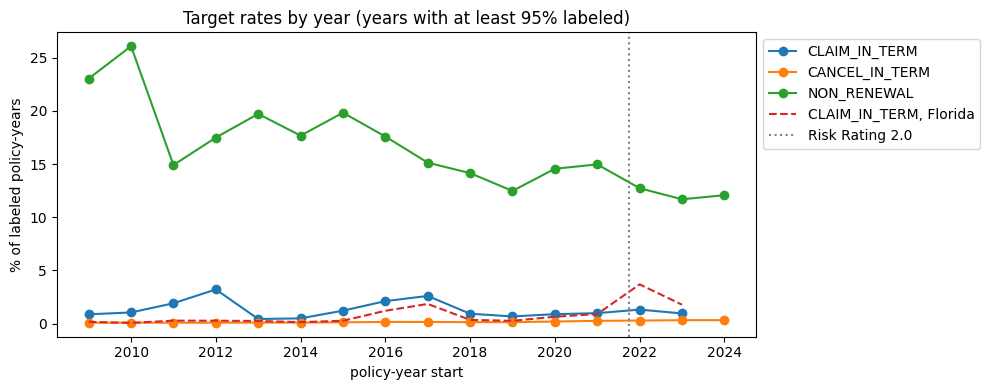

,claim_pct,cancel_pct,non_renewal_pct
period_year,,,
2022,0.992,1.000,0.994
2023,0.994,1.000,0.996
2024,0.692,1.000,0.998
2025,0.005,0.702,0.510
2026,0.000,0.005,0.004


In [58]:
# Step 10.4c Chart: only years where at least 95% of the policy-years are labeled for that target
MIN_LABELED = 0.95
n_last = con.sql("SELECT period_year, COUNT(*) FILTER (WHERE is_last_period) AS last_periods "
                 "FROM periods_all GROUP BY 1").df().set_index("period_year")["last_periods"]
ry = rates_year.set_index("period_year")
share = {"claim_pct": ry["claim_labeled"] / ry["periods"],
         "cancel_pct": ry["cancel_labeled"] / ry["periods"],
         "non_renewal_pct": ry["non_renewal_labeled"] / n_last.reindex(ry.index)}

fig, ax = plt.subplots(figsize=(10, 4))
for col, label in [("claim_pct", "CLAIM_IN_TERM"), ("cancel_pct", "CANCEL_IN_TERM"),
                   ("non_renewal_pct", "NON_RENEWAL")]:
    y = ry[col].where(share[col] >= MIN_LABELED)          # hide censored years
    ax.plot(ry.index, y, marker="o", label=label)
fl = rates_state_year[rates_state_year["propertyState"] == "FL"].set_index("period_year")
fl_y = fl["claim_pct"].where(fl["claim_labeled"] / fl["periods"] >= MIN_LABELED)
ax.plot(fl.index, fl_y, linestyle="--", label="CLAIM_IN_TERM, Florida")
ax.axvline(2021.75, color="grey", linestyle=":", label="Risk Rating 2.0")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set(xlabel="policy-year start", ylabel="% of labeled policy-years",
       title=f"Target rates by year (years with at least {MIN_LABELED:.0%} labeled)")
ax.legend(bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(REPORTS / "fig_target_rates_by_year.png", dpi=150)
plt.show()

pd.DataFrame(share).round(3).tail(5)      # labeled share per target, last years

> **Our findings:**
>
> - **The claim rate is about 1% nationally, as our README expected, but it moves with storms.** It is 0.4–1.3% in quiet years and peaks in 2012 (3.2%, Sandy), 2016–2017 (2.1–2.6%, Matthew and Harvey/Irma) and 2024 (2.4%, partly labeled). Florida is lower than the nation in most years (0.1–0.3% before 2016) but far higher in its storm years: 1.8% (2017, Irma), 3.7% (2022, Ian) and 6.1% (2024, Helene and Milton). A single storm year can dominate a state's training data.
> - **Mid-term lapses rose but stay rare:** from about 0.08% (2009–2014) to about 0.3% (2022–2024), with the rise starting before Risk Rating 2.0. Sales and removals are much more common (1.5–3.2%).
> - **Non-renewal is the main way policies leave:** about 23–26% in 2009–2010, falling to about 12–15% after 2018. It does not jump visibly at Risk Rating 2.0 (October 2021).
> - **The last years are censored, not real.** For policy-years starting in 2025–2026, only the policies that already left are labeled, so their cancel and non-renewal rates look very high (2026: 18.5% lapse, about 100% non-renewal). Claims are labeled only up to 2024, and 2024 only partly. The chart hides any year with less than 95% labeled. We use claims up to 2023 and lapse/non-renewal up to 2024 at most.

#### 10.5 Spot-check rebuilt policies
We read 10 rebuilt policies end to end (terms, claims, cancellations) to confirm that the linkage makes sense.

In [57]:
# Step 10.5 10 random policies with at least 3 terms, from all states
keys = con.sql('''SELECT DISTINCT policy_key FROM periods_all
                  WHERE n_terms_key >= 3 ORDER BY hash(policy_key) LIMIT 10''').df()["policy_key"]
for k in keys:
    display(con.sql(f'''
        SELECT propertyState, term_no, period_no, period_start, period_end, ROUND(exposure, 2) AS exposure,
               cancel_category, claim_count, CLAIM_IN_TERM, CANCEL_IN_TERM, NON_RENEWAL, dq_key_collision
        FROM periods_all WHERE policy_key = {int(k)} ORDER BY period_start
    ''').df())

,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,CA,1,0,2011-04-08,2012-04-08,1.0,not_cancelled,0,0,0,0,False
1,CA,2,0,2012-04-08,2013-04-08,1.0,not_cancelled,0,0,0,0,False
2,CA,3,0,2013-04-08,2014-04-08,1.0,not_cancelled,0,0,0,0,False
3,CA,4,0,2014-04-08,2015-04-08,1.0,not_cancelled,0,0,0,0,False
4,CA,5,0,2015-04-08,2016-04-08,1.0,not_cancelled,0,0,0,0,False
5,CA,6,0,2016-04-08,2017-04-08,1.0,not_cancelled,0,0,0,0,False
6,CA,7,0,2017-04-08,2018-04-08,1.0,not_cancelled,0,0,0,0,False
7,CA,8,0,2018-04-08,2019-04-08,1.0,not_cancelled,0,0,0,0,False
8,CA,9,0,2019-04-08,2020-04-08,1.0,not_cancelled,0,0,0,0,False
9,CA,10,0,2020-04-08,2021-04-08,1.0,not_cancelled,0,0,0,0,False


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,FL,1,0,2019-03-03,2020-03-03,1.0,not_cancelled,0,0,0,0,False
1,FL,2,0,2020-03-03,2021-03-03,1.0,not_cancelled,0,0,0,0,False
2,FL,3,0,2021-03-03,2022-03-03,1.0,not_cancelled,0,0,0,0,False
3,FL,4,0,2022-03-03,2023-03-03,1.0,not_cancelled,0,0,0,0,False
4,FL,5,0,2023-03-03,2024-03-03,1.0,not_cancelled,0,0,0,0,False
5,FL,6,0,2024-03-03,2025-03-03,1.0,not_cancelled,0,0,0,0,False
6,FL,7,0,2025-03-03,2026-03-03,1.0,not_cancelled,0,<NA>,0,0,False
7,FL,8,0,2026-03-03,2027-03-03,1.0,not_cancelled,0,<NA>,<NA>,<NA>,False


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,FL,1,0,2021-08-18,2022-08-18,1.0,not_cancelled,0,0,0,0,False
1,FL,2,0,2022-08-18,2023-08-18,1.0,not_cancelled,0,0,0,0,False
2,FL,3,0,2023-08-18,2024-08-18,1.0,not_cancelled,0,0,0,0,False
3,FL,4,0,2024-08-18,2025-08-18,1.0,not_cancelled,0,0,0,0,False
4,FL,5,0,2025-08-18,2026-08-18,1.0,not_cancelled,0,<NA>,0,<NA>,False
5,FL,6,0,2026-08-18,2027-08-18,1.0,not_cancelled,0,<NA>,<NA>,<NA>,False


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,MD,1,0,2009-09-24,2010-09-24,1.0,not_cancelled,0,0,0,0,False
1,MD,2,0,2010-09-24,2011-09-24,1.0,not_cancelled,0,0,0,0,False
2,MD,3,0,2011-09-24,2012-09-24,1.0,not_cancelled,0,0,0,1,False
3,MD,4,0,2016-09-24,2017-09-24,1.0,not_cancelled,0,0,0,0,False
4,MD,5,0,2017-09-24,2018-09-24,1.0,not_cancelled,0,0,0,0,False
5,MD,6,0,2018-09-24,2019-09-24,1.0,not_cancelled,0,0,0,0,False
6,MD,7,0,2019-09-24,2020-09-24,1.0,not_cancelled,0,0,0,0,False
7,MD,8,0,2020-09-24,2021-09-24,1.0,not_cancelled,0,0,0,0,False
8,MD,9,0,2021-09-24,2022-09-24,1.0,not_cancelled,0,0,0,0,False
9,MD,10,0,2022-09-24,2023-09-24,1.0,not_cancelled,0,0,0,0,False


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,NJ,1,0,2014-10-03,2015-10-03,1.0,not_cancelled,0,0,0,0,False
1,NJ,2,0,2015-10-03,2016-10-03,1.0,not_cancelled,0,0,0,0,False
2,NJ,3,0,2016-10-03,2017-10-03,1.0,not_cancelled,0,0,0,0,False
3,NJ,4,0,2017-10-03,2018-10-03,1.0,not_cancelled,0,0,0,1,False


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,MI,1,0,2009-03-03,2010-03-03,1.0,not_cancelled,0,0,0,0,False
1,MI,2,0,2010-03-03,2011-03-03,1.0,not_cancelled,0,0,0,0,False
2,MI,3,0,2011-03-03,2012-03-03,1.0,not_cancelled,0,0,0,0,False
3,MI,4,0,2012-03-03,2013-03-03,1.0,not_cancelled,0,0,0,1,False
4,MI,5,0,2017-03-03,2018-03-03,1.0,not_cancelled,0,0,0,0,False
5,MI,6,0,2018-03-03,2019-03-03,1.0,not_cancelled,0,0,0,0,False
6,MI,7,0,2019-03-03,2020-03-03,1.0,not_cancelled,0,0,0,0,False
7,MI,8,0,2020-03-03,2021-03-03,1.0,not_cancelled,0,0,0,0,False
8,MI,9,0,2021-03-03,2022-03-03,1.0,not_cancelled,0,0,0,0,False
9,MI,10,0,2022-03-03,2023-03-03,1.0,not_cancelled,0,0,0,0,False


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,FL,1,0,2016-07-05,2017-07-05,1.0,not_cancelled,0,0,0,1,False
1,FL,2,0,2017-10-06,2018-10-06,1.0,not_cancelled,0,0,0,0,False
2,FL,3,0,2018-10-06,2019-10-06,1.0,not_cancelled,0,0,0,0,False
3,FL,4,0,2019-10-06,2020-10-06,1.0,not_cancelled,0,0,0,0,False
4,FL,5,0,2020-10-06,2021-10-06,1.0,not_cancelled,0,0,0,0,False
5,FL,6,0,2021-10-06,2022-10-06,1.0,not_cancelled,0,0,0,0,False
6,FL,7,0,2022-10-06,2023-10-06,1.0,not_cancelled,0,0,0,0,False
7,FL,8,0,2023-10-06,2024-10-06,1.0,not_cancelled,0,0,0,0,False
8,FL,9,0,2024-10-06,2025-10-06,1.0,not_cancelled,0,<NA>,0,0,False
9,FL,10,0,2025-10-06,2026-10-06,1.0,not_cancelled,0,<NA>,<NA>,<NA>,False


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,MI,1,0,2012-06-01,2013-06-01,1.0,not_cancelled,0,0,0,0,False
1,MI,2,0,2013-06-01,2014-06-01,1.0,not_cancelled,0,0,0,0,False
2,MI,3,0,2014-06-01,2015-06-01,1.0,not_cancelled,0,0,0,0,False
3,MI,4,0,2015-06-01,2016-06-01,1.0,not_cancelled,0,0,0,0,False
4,MI,5,0,2016-06-01,2017-06-01,1.0,not_cancelled,0,0,0,0,False
5,MI,6,0,2017-06-01,2018-06-01,1.0,not_cancelled,0,0,0,0,False
6,MI,7,0,2018-06-01,2019-06-01,1.0,not_cancelled,0,0,0,0,False
7,MI,8,0,2019-06-01,2020-06-01,1.0,not_cancelled,0,0,0,0,False
8,MI,9,0,2020-06-01,2021-06-01,1.0,not_cancelled,0,0,0,0,False
9,MI,10,0,2021-06-01,2022-06-01,1.0,not_cancelled,0,0,0,0,False


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,MA,1,0,2009-10-24,2010-10-24,1.0,not_cancelled,0,0,0,0,False
1,MA,2,0,2010-10-24,2011-10-24,1.0,not_cancelled,0,0,0,0,False
2,MA,3,0,2011-10-24,2012-10-24,1.0,not_cancelled,0,0,0,0,False
3,MA,4,0,2012-10-24,2013-10-24,1.0,not_cancelled,0,0,0,1,False
4,MA,5,0,2014-02-19,2015-02-19,1.0,not_cancelled,0,0,0,1,False


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,FL,1,0,2009-06-25,2010-06-25,1.0,not_cancelled,0,0,0,0,False
1,FL,2,0,2010-06-25,2011-06-25,1.0,not_cancelled,0,0,0,0,False
2,FL,3,0,2011-06-25,2012-06-25,1.0,not_cancelled,0,0,0,0,False
3,FL,4,0,2012-06-25,2013-06-25,1.0,not_cancelled,0,0,0,1,False
4,FL,5,0,2013-09-19,2014-09-19,1.0,not_cancelled,0,0,0,0,False
5,FL,6,0,2014-09-19,2015-09-19,1.0,not_cancelled,0,0,0,0,False
6,FL,7,0,2015-09-19,2016-09-19,1.0,not_cancelled,0,0,0,0,False
7,FL,8,0,2016-09-19,2017-09-19,1.0,not_cancelled,0,0,0,1,False


In [59]:
# Step 10.5b One policy of each kind: collision, claim, lapse, multi-year, gap-and-return
cases = {
    "collision":  "dq_key_collision",
    "claim":      "claim_count > 0",
    "lapse":      "CANCEL_IN_TERM = 1",
    "multi-year": "n_scheduled > 1",
    "gap/return": "NON_RENEWAL = 1 AND term_no < n_terms_key",
}
for name, cond in cases.items():
    k = scalar(con, f"SELECT policy_key FROM periods_all WHERE {cond} AND policy_key IS NOT NULL "
                    f"ORDER BY hash(policy_key) LIMIT 1")
    print(f"\n=== {name} ===")
    if k is None:
        print("none found"); continue
    display(con.sql(f'''
        SELECT propertyState, term_no, period_no, period_start, period_end, ROUND(exposure, 2) AS exposure,
               cancel_category, claim_count, CLAIM_IN_TERM, CANCEL_IN_TERM, NON_RENEWAL, dq_key_collision
        FROM periods_all WHERE policy_key = {int(k)} ORDER BY period_start, term_no
    ''').df())


=== collision ===


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,MS,1,0,2012-04-20,2013-04-20,1.0,not_cancelled,0,0,0,0,True
1,MS,2,0,2012-04-20,2013-04-20,1.0,not_cancelled,0,0,0,0,True
2,MS,3,0,2012-04-20,2013-04-20,1.0,not_cancelled,0,0,0,0,True
3,MS,4,0,2012-04-20,2013-04-20,1.0,not_cancelled,0,0,0,0,True
4,MS,5,0,2012-04-20,2013-04-20,1.0,not_cancelled,0,0,0,0,True
...,...,...,...,...,...,...,...,...,...,...,...,...
91,MS,92,0,2017-04-20,2018-04-20,1.0,not_cancelled,0,0,0,1,True
92,MS,93,0,2017-04-20,2018-04-20,1.0,not_cancelled,0,0,0,1,True
93,MS,94,0,2017-04-20,2018-04-20,1.0,not_cancelled,0,0,0,1,True
94,MS,95,0,2017-04-20,2018-04-20,1.0,not_cancelled,0,0,0,1,True



=== claim ===


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,TX,1,0,2013-06-29,2014-06-29,1.0,not_cancelled,0,0,0,0,False
1,TX,2,0,2014-06-29,2015-06-29,1.0,not_cancelled,1,1,0,0,False
2,TX,3,0,2015-06-29,2016-06-29,1.0,not_cancelled,0,0,0,0,False
3,TX,4,0,2016-06-29,2017-06-29,1.0,not_cancelled,0,0,0,0,False
4,TX,5,0,2017-06-29,2018-06-29,1.0,not_cancelled,0,0,0,0,False
5,TX,6,0,2018-06-29,2019-06-29,1.0,not_cancelled,0,0,0,0,False
6,TX,7,0,2019-06-29,2020-06-29,1.0,not_cancelled,0,0,0,0,False
7,TX,8,0,2020-06-29,2021-06-29,1.0,not_cancelled,0,0,0,0,False
8,TX,9,0,2021-06-29,2022-06-29,1.0,not_cancelled,0,0,0,0,False
9,TX,10,0,2022-06-29,2023-06-29,1.0,not_cancelled,0,0,0,0,False



=== lapse ===


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,OH,1,0,2016-06-24,2017-06-24,1.00,not_cancelled,0,0,0,0,False
1,OH,2,0,2017-06-24,2018-06-24,1.00,not_cancelled,0,0,0,0,False
2,OH,3,0,2018-06-24,2019-06-24,1.00,not_cancelled,0,0,0,0,False
3,OH,4,0,2019-06-24,2020-06-24,1.00,not_cancelled,0,0,0,0,False
4,OH,5,0,2020-06-24,2021-06-24,1.00,not_cancelled,0,0,0,0,False
5,OH,6,0,2021-06-24,2021-10-05,0.28,lapse,0,0,1,1,False



=== multi-year ===


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,CA,1,0,2009-10-05,2010-10-05,1.0,not_cancelled,0,0,0,0,False
1,CA,1,1,2010-10-05,2011-10-05,1.0,not_cancelled,0,0,0,1,False



=== gap/return ===


,propertyState,term_no,period_no,period_start,period_end,exposure,cancel_category,claim_count,CLAIM_IN_TERM,CANCEL_IN_TERM,NON_RENEWAL,dq_key_collision
0,MD,1,0,2009-09-24,2010-09-24,1.0,not_cancelled,0,0,0,0,False
1,MD,2,0,2010-09-24,2011-09-24,1.0,not_cancelled,0,0,0,0,False
2,MD,3,0,2011-09-24,2012-09-24,1.0,not_cancelled,0,0,0,1,False
3,MD,4,0,2016-09-24,2017-09-24,1.0,not_cancelled,0,0,0,0,False
4,MD,5,0,2017-09-24,2018-09-24,1.0,not_cancelled,0,0,0,0,False
5,MD,6,0,2018-09-24,2019-09-24,1.0,not_cancelled,0,0,0,0,False
6,MD,7,0,2019-09-24,2020-09-24,1.0,not_cancelled,0,0,0,0,False
7,MD,8,0,2020-09-24,2021-09-24,1.0,not_cancelled,0,0,0,0,False
8,MD,9,0,2021-09-24,2022-09-24,1.0,not_cancelled,0,0,0,0,False
9,MD,10,0,2022-09-24,2023-09-24,1.0,not_cancelled,0,0,0,0,False


> **Our findings:**
>
> - **All 10 rebuilt policies look right.** Each is a chain of one-year terms on the same anniversary date (for example every 8 April from 2011 to 2023), up to 15 terms long. None has a key collision. That is expected: only about 3.4% of terms are flagged, so a random sample of 10 rarely shows one; Sections 6.1 and 10.2 measure the collision rate on all terms.
> - **Censoring works at the end of the data.** The most recent policy-years have `CLAIM_IN_TERM` NULL (within 365 days of the cutoff), and the term still running at the cutoff is NULL for all three targets.
> - **Leaving and returning is common.** Five of the 10 houses were uninsured for a while (3 months to 4 years) and then came back under the same key. We label the year before the gap `NON_RENEWAL = 1`, which is correct by our rule. One Florida house was uninsured during Hurricane Irma (September 2017) and returned in October 2017.
> - **What this sample does not test:** none of the 10 had a claim, a cancellation or a multi-year term, so we check those cases in Step 10.5b.
> - **Small issue noted:** a renewal that is already visible is still NULL when its 60-day window closes after the cutoff (one Florida term renewed on 2026-08-18). Labeling these as 0 would recover some recent labels.

### Section 11. Export
We save the labeled table, the linkage report and our decisions note.

#### 11.1 The labeled table
We already saved the labeled table, one file per state, in `data/processed/periods/`. In notebook 04 we read it with `read_parquet('data/processed/periods/*.parquet')` and join the features from `policies_clean` by `id`.

| Column | Meaning |
|---|---|
| `id` | policy term id (join key to `policies_clean`) |
| `period_id`, `period_no` | the policy-year: `id` + number within the term (0, 1, 2) |
| `policy_key`, `term_no`, `n_terms_key` | rebuilt policy and the term's place in it |
| `period_start`, `period_end`, `exposure`, `period_year` | the policy-year and its length in years |
| `is_last_period`, `n_scheduled` | last policy-year of the term; scheduled number of policy-years |
| `term_start`, `term_end`, `eff_end`, `cancel_date`, `cancel_code`, `cancel_category` | the term and its cancellation (**target-only**) |
| `claim_count`, `paid_claim_count`, `claim_paid_total`, `first_loss_date` | claims in the policy-year (**target-only**) |
| `CLAIM_IN_TERM`, `CLAIM_PAID_IN_TERM`, `CANCEL_IN_TERM`, `SOLD_REMOVED_IN_TERM`, `NON_RENEWAL` | targets (NULL = unknown) |
| `censored_claim`, `censored_cancel`, `censored_renewal` | why a target is NULL |
| `key_complete`, `dq_key_collision`, `community_sanctioned` | linkage and label quality flags for notebook 04 |

In [60]:
# Step 11.1 Log the linkage
n_void_dup = int(waterfall.loc["void_or_duplicate", "rows"])
n_key_incomplete = scalar(con, "SELECT COUNT(*) FROM periods_all WHERE period_no = 0 AND NOT key_complete")
n_collision = scalar(con, "SELECT COUNT(*) FROM periods_all WHERE period_no = 0 AND dq_key_collision")
n_multi = scalar(con, "SELECT COUNT(*) FROM periods_all WHERE period_no = 0 AND n_scheduled > 1")
n_after_cutoff = int(waterfall.loc["starts_after_cutoff", "rows"])
n_matched = scalar(con, "SELECT COUNT(*) FROM links_all WHERE term_id IS NOT NULL")

log.add("policies", "cancel_category", "void and duplicate terms left out of the policy-years",
        "never real cover; would double-count exposure and claims", n_void_dup)
log.add("policies", "cancellationDateOfFloodPolicy", "flat cancellations (on or before the start) left out",
        "the term never gave cover; an unpaid renewal becomes NON_RENEWAL of the term before",
        int(waterfall.loc["flat_cancelled", "rows"]))
log.add("policies", "policyEffectiveDate", "terms starting after the cutoff left out",
        f"after asOfDate {CUTOFF}", n_after_cutoff)
log.add("policies", "policy key", "key incomplete: claim and renewal targets NULL",
        "a key field is missing, so the term can't be linked", n_key_incomplete)
log.add("policies", "policy key", "flag dq_key_collision",
        "more than one term of the key starts in the same year", n_collision)
log.add("policies", "policyEffectiveDate / policyTerminationDate", "split multi-year terms into policy-years",
        "unit of prediction is the policy-year (option B)", n_multi)
log.add("claims", "policy key + dateOfLoss", "link claim to policy-year",
        "claim target", n_matched)
for col in ("censored_claim", "censored_cancel", "censored_renewal"):
    log.add("periods", col, "target set to NULL", "outcome not observable before the cutoff",
            scalar(con, f"SELECT COUNT(*) FROM periods_all WHERE {col}"))
linkage_log = log.to_frame()
linkage_log

,table,column,rule,reason,rows_affected
0,policies,cancellationVoidanceReasonCode,decode to cancel_category (src/targets.py),"lapse = 05, 28, 30, 52; rewrites, duplicates a...",3153279
1,policies,cancel_category,void and duplicate terms left out of the polic...,never real cover; would double-count exposure ...,282869
2,policies,cancellationDateOfFloodPolicy,flat cancellations (on or before the start) le...,the term never gave cover; an unpaid renewal b...,1132211
3,policies,policyEffectiveDate,terms starting after the cutoff left out,after asOfDate 2026-09-08,215179
4,policies,policy key,key incomplete: claim and renewal targets NULL,"a key field is missing, so the term can't be l...",366192
5,policies,policy key,flag dq_key_collision,more than one term of the key starts in the sa...,3941389
6,policies,policyEffectiveDate / policyTerminationDate,split multi-year terms into policy-years,unit of prediction is the policy-year (option B),85337
7,claims,policy key + dateOfLoss,link claim to policy-year,claim target,982116
8,periods,censored_claim,target set to NULL,outcome not observable before the cutoff,6992287
9,periods,censored_cancel,target set to NULL,outcome not observable before the cutoff,3380428


#### 11.2 Save the linkage report
We save every table from this notebook as a CSV, plus one Excel workbook with a sheet per table.

In [61]:
# Step 11.2 Reports
outputs = {
    "linkage_log.csv": linkage_log,
    "linkage_waterfall.csv": waterfall.reset_index(names="step"),
    "linkage_alt_keys.csv": alt_keys,
    "linkage_quality_terms_by_state.csv": quality_terms,
    "linkage_quality_claims_by_state.csv": quality_claims,
    "linkage_quality_claims_by_year.csv": quality_claims_year,
    "target_rates_by_year.csv": rates_year,
    "target_rates_by_state_year.csv": rates_state_year,
}
for name, df in outputs.items():
    df.to_csv(REPORTS / name, index=False)
    print("saved", name)

with pd.ExcelWriter(REPORTS / "linkage_and_targets_report.xlsx") as xw:
    for name, df in outputs.items():
        df.to_excel(xw, sheet_name=name.removesuffix(".csv")[:31], index=False)

saved linkage_log.csv
saved linkage_waterfall.csv
saved linkage_alt_keys.csv
saved linkage_quality_terms_by_state.csv
saved linkage_quality_claims_by_state.csv
saved linkage_quality_claims_by_year.csv
saved target_rates_by_year.csv
saved target_rates_by_state_year.csv


#### 11.3 Linkage decisions note
We write a short markdown file in `docs/`, like our notebook 02 cleaning note. We fill in the `...` lines before submitting.

In [62]:
# Step 11.3 Linkage decisions note
q = con.sql(term_quality_sql("periods_all")).df().iloc[0]
m = con.sql(claim_match_sql("links_all")).df().iloc[0]

note = f'''# Linkage and target decisions (notebook 03)

## Summary
- Data cutoff: {CUTOFF} (asOfDate of the FEMA files).
- {int(waterfall.loc["terms_clean", "rows"]):,} clean policy terms -> {int(waterfall.loc["terms_labeled", "rows"]):,} linked terms -> {int(waterfall.loc["policy_years", "rows"]):,} policy-years.
- Policy key: {", ".join(KEY)}. Key complete for {q["key_complete_pct"]}% of terms; {q["collision_pct"]}% of terms are in a collision.
- Claims with a loss from 2010 on: {m["matched_pct"] + m["matched_multi_pct"]:.1f}% linked to a policy-year.
- Claim reporting delay: {CLAIM_LAG_DAYS} days. Renewal window: +/-{RENEWAL_WINDOW_DAYS} days.

## Key decisions
<!-- Write 1-2 sentences for each: what you decided and why -->
- **Unit of prediction:** the policy-year. Multi-year terms are split by their dates (option B); short last periods are kept with exposure below 1.
- **Lapse codes:** 05, 28, 30 and 52. ...
- **Void and duplicate terms:** left out. ...
- **Flat cancellations:** terms cancelled on or before their start date are left out; an unpaid renewal counts as NON_RENEWAL of the term before, and CANCEL_IN_TERM measures lapses during a term. ...
- **Policy key:** ... (Section 6.2)
- **Claim reporting delay:** ... (Section 7.1)
- **Collisions:** ...

## Left for later notebooks
- Notebook 04: exclude or keep `dq_key_collision`, `community_sanctioned` and multi-unit rows; which lapse target to model (CANCEL_IN_TERM, NON_RENEWAL or both).
- Notebook 05: features are joined from `policies_clean` by `id`. Cancellation and claim columns in the labeled table are target-only.
'''
(DOCS / "linkage_decisions.md").write_text(note)
print(note)

# Linkage and target decisions (notebook 03)

## Summary
- Data cutoff: 2026-09-08 (asOfDate of the FEMA files).
- 74,739,461 clean policy terms -> 73,108,634 linked terms -> 73,248,304 policy-years.
- Policy key: originalNBDate, originalConstructionDate, censusGeoid, reportedZipCode, numberOfFloorsInInsuredBuilding. Key complete for 99.5% of terms; 5.42% of terms are in a collision.
- Claims with a loss from 2010 on: 98.3% linked to a policy-year.
- Claim reporting delay: 365 days. Renewal window: +/-60 days.

## Key decisions
<!-- Write 1-2 sentences for each: what you decided and why -->
- **Unit of prediction:** the policy-year. Multi-year terms are split by their dates (option B); short last periods are kept with exposure below 1.
- **Lapse codes:** 05, 28, 30 and 52. ...
- **Void and duplicate terms:** left out. ...
- **Flat cancellations:** terms cancelled on or before their start date are left out; an unpaid renewal counts as NON_RENEWAL of the term before, and CANCEL_IN_TERM m